<a href="https://colab.research.google.com/github/Damian-Swaczyna/cpp/blob/master/pl/lab_auto_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium 5: sieci projektowe — CPM, PERT i wykresy Gantta

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_5.ipynb)

W laboratorium 4 planowaliśmy operacje w komórce robotycznej. Było to **harmonogramowanie typu job-shop**: zadania konkurowały o fizyczne stanowiska, więc zmienne binarne wybierały kolejność ich obsługi.

Teraz patrzymy na cały projekt. Zespół robotyki ma przygotować działający pokaz. Pytamy:

- Które zadania projektowe mogą przebiegać równolegle?
- Które wyznaczają najwcześniejszy termin ukończenia?
- Które opóźnienia nie wpływają na zakończenie, a które przesuwają cały projekt?
- Kiedy warto zapłacić za szybszą dostawę lub dodatkowe ograniczenie ryzyka?

Wykorzystamy:

- **metodę ścieżki krytycznej (CPM)** dla ustalonych czasów zadań,
- **PERT** dla niepewnych czasów zadań,
- **wykresy Gantta** do przedstawiania harmonogramu i zapasu czasu.

## Cele ćwiczenia

Po wykonaniu zadań potrafisz:

1. zapisać opis projektu robotycznego jako zadania, czasy i ograniczenia kolejności,
2. obliczyć najwcześniejsze i najpóźniejsze początki/końce, zapas czasu i ścieżkę krytyczną,
3. wyjaśnić, dlaczego przyspieszenie zadania niekrytycznego może oszczędzić **zero** dni projektu,
4. narysować i odczytać projektowy wykres Gantta,
5. wykorzystać oszacowania PERT do przybliżonej oceny ryzyka niedotrzymania terminu,
6. porównać szybsze dostawy, skracanie czasu zadań i działania zmniejszające ryzyko.

## Scenariusz: pokaz autonomicznego robota inspekcyjnego

Laboratorium przygotowuje autonomicznego robota inspekcyjnego na dzień otwarty. Robot ma poruszać się w niewielkiej komórce produkcyjnej, sprawdzić część i przekazać wynik gościom.

Kierownictwo chce, jeśli to możliwe, skrócić plan deterministyczny do **30 dni**. Zespół może:

1. wybrać szybszego, droższego dostawcę wybranych podzespołów,
2. skrócić wybrane prace inżynierskie dzięki dodatkowym osobom lub nadgodzinom,
3. dodać krótki przegląd zmniejszający ryzyko, który na wykresie Gantta wygląda jak dodatkowa praca, lecz może ograniczyć późniejszą niepewność.

Pytanie brzmi: „Która decyzja skraca **ścieżkę krytyczną** lub zmniejsza ryzyko na tyle, by uzasadnić koszt?”. Samo przyspieszenie pojedynczego zadania nie wystarcza.

## Widok projektu

![Planowanie projektu autonomicznego robota inspekcyjnego](https://raw.githubusercontent.com/AdoHaha/automation_robotics_lab/refs/heads/master/lab_auto_5_illustration.png)

Ta sama ilustracja znajduje się w głównym katalogu repozytorium jako `lab_auto_5_illustration.png`, jeśli środowisko korzysta z lokalnych plików.

## Rozgrzewka na papierze: sieć czterech zadań

Przed uruchomieniem Pythona rozwiąż przykład ręcznie. Poznaj cztery oznaczenia czasów CPM, zanim przeczytasz implementację.

- **ES** (*earliest start*, najwcześniejszy początek): najwcześniejszy dzień rozpoczęcia po zakończeniu wszystkich poprzedników.
- **EF** (*earliest finish*, najwcześniejszy koniec): `ES + duration`.
- **LF** (*latest finish*, najpóźniejszy koniec): najpóźniejszy dzień zakończenia bez opóźniania projektu.
- **LS** (*latest start*, najpóźniejszy początek): `LF - duration`.
- **Zapas czasu** (`slack`): `LS - ES`. Zerowy zapas oznacza zadanie krytyczne.

| Zadanie | Czas trwania | Poprzednicy |
|:---:|---:|:---|
| A | 2 | — |
| B | 3 | — |
| C | 5 | A, B |
| D | 4 | C |

Odpowiedz bez kodu:

1. Jakie są ES i EF każdego zadania?
2. Jakie są LS i LF, jeśli projekt kończy się możliwie najwcześniej?
3. Które zadania mają zerowy zapas czasu?
4. Jaka jest ścieżka krytyczna?
5. Czy skrócenie A o 1 dzień przyspiesza projekt? Dlaczego?

Wskazówki:

- W przejściu w przód zadania bez poprzedników rozpoczynają się w dniu 0.
- Gdy zadanie ma kilku poprzedników, jego ES wyznacza największe EF poprzednika.
- Najwcześniejszy koniec projektu to EF ostatniego zadania.
- W przejściu wstecz zaczynamy od najwcześniejszego końca projektu i cofamy się przez sieć.
- Zadanie jest krytyczne, gdy zapas czasu wynosi zero. Ścieżka krytyczna musi tworzyć połączony łańcuch od początku do końca projektu.
- Aby ocenić skrócenie A, sprawdź, czy to A wyznacza początek C.

> **Moje odpowiedzi do rozgrzewki (bez kodu).**
>
> | Zadanie | Czas | ES | EF | LS | LF | Zapas |
> |:---:|---:|---:|---:|---:|---:|---:|
> | A | 2 | 0 | 2 | 1 | 3 | **1** |
> | B | 3 | 0 | 3 | 0 | 3 | 0 |
> | C | 5 | 3 | 8 | 3 | 8 | 0 |
> | D | 4 | 8 | 12 | 8 | 12 | 0 |
>
> 1. **ES/EF:** A i B startują w dniu 0 (EF 2 i 3). C czeka na **późniejszego** poprzednika, czyli B: ES = max(2, 3) = 3, EF = 8. D: ES = 8, EF = 12.
> 2. **LS/LF** (koniec projektu = 12): D: LF 12, LS 8; C: LF 8, LS 3; A i B: LF = LS(C) = 3, więc LS(A) = 1, LS(B) = 0.
> 3. **Zerowy zapas:** B, C i D. A ma 1 dzień zapasu.
> 4. **Ścieżka krytyczna:** **B → C → D** (3 + 5 + 4 = 12 dni).
> 5. **Skrócenie A o 1 dzień nie przyspiesza projektu.** Początek C wyznacza B (kończy się w dniu 3), a nie A (dzień 2). A ma już zapas, więc kończy się jeszcze wcześniej, a C i tak czeka na B.

## Importy i konfiguracja środowiska

Notebook działa w Google Colab i lokalnym Jupyterze. Uruchom następną komórkę. Jeśli brakuje pakietu, komórka instaluje potrzebne biblioteki w bieżącym środowisku notebooka.

In [1]:
# W Colab i lokalnym Jupyterze używamy tych samych bibliotek; instalujemy je po nieudanym imporcie.
try:
    from itertools import product
    from math import erf, sqrt

    import matplotlib.pyplot as plt
    import networkx as nx
    import numpy as np
    import pandas as pd
except ModuleNotFoundError:
    # W Colab pakiety instalują się w środowisku notebooka.
    # Lokalnie najlepiej użyć środowiska wirtualnego i `pip install -r requirements.txt`.
    %pip install numpy pandas matplotlib networkx

    from itertools import product
    from math import erf, sqrt

    import matplotlib.pyplot as plt
    import networkx as nx
    import numpy as np
    import pandas as pd


## Dane głównego projektu

Czasy są podane w **dniach**. Kolumna `predecessors` zawiera zadania, które muszą się zakończyć przed rozpoczęciem danego zadania.

Kolumny `a`, `m` i `b` to oszacowania PERT:

- `a`: czas optymistyczny,
- `m`: czas najbardziej prawdopodobny,
- `b`: czas pesymistyczny.

W CPM najpierw wykorzystamy ustaloną kolumnę `duration`. W PERT obliczymy czas oczekiwany na podstawie `a`, `m` i `b`.

Nazwy kolumn i kluczy pozostają zgodne z kodem: `id` — identyfikator, `task` — opis zadania, `owner` — odpowiedzialny zespół, `duration` — czas trwania. `ES`, `EF`, `LS`, `LF` oznaczają czasy CPM, `slack` — zapas czasu, `critical` — oznaczenie zadania krytycznego, a `successors` — następniki.

In [2]:
# Przechowuj czasy deterministyczne i PERT razem, aby obie analizy korzystały z tych samych zależności.
project_tasks = pd.DataFrame([
    {
        "id": "A",
        "task": 'Określenie wymagań pokazu',
        "owner": 'Kierownik projektu',
        "duration": 2,
        "predecessors": [],
        "a": 1,
        "m": 2,
        "b": 3,
    },
    {
        "id": "B",
        "task": 'Zatwierdzenie bezpieczeństwa obszaru testów',
        "owner": 'Specjalista ds. bezpieczeństwa',
        "duration": 4,
        "predecessors": ["A"],
        "a": 3,
        "m": 4,
        "b": 7,
    },
    {
        "id": "C",
        "task": 'Architektura oprogramowania i interfejsy',
        "owner": 'Zespół oprogramowania',
        "duration": 4,
        "predecessors": ["A"],
        "a": 3,
        "m": 4,
        "b": 7,
    },
    {
        "id": "D",
        "task": 'Dostawa czujnika LiDAR',
        "owner": 'Dział zakupów',
        "duration": 8,
        "predecessors": ["A"],
        "a": 5,
        "m": 8,
        "b": 13,
    },
    {
        "id": "E",
        "task": 'Dostawa modułu akumulatora',
        "owner": 'Dział zakupów',
        "duration": 5,
        "predecessors": ["A"],
        "a": 3,
        "m": 5,
        "b": 9,
    },
    {
        "id": "F",
        "task": 'Budowa podwozia',
        "owner": 'Zespół mechaniczny',
        "duration": 6,
        "predecessors": ["A"],
        "a": 4,
        "m": 6,
        "b": 9,
    },
    {
        "id": "G",
        "task": 'Przygotowanie scenariusza symulacji',
        "owner": 'Zespół symulacji',
        "duration": 4,
        "predecessors": ["B", "C"],
        "a": 3,
        "m": 4,
        "b": 6,
    },
    {
        "id": "H",
        "task": 'Montaż elektroniki i układu percepcji',
        "owner": 'Zespół integracji',
        "duration": 5,
        "predecessors": ["D", "E", "F"],
        "a": 4,
        "m": 5,
        "b": 9,
    },
    {
        "id": "I",
        "task": 'Integracja oprogramowania nawigacji',
        "owner": 'Zespół oprogramowania',
        "duration": 6,
        "predecessors": ["C", "H"],
        "a": 4,
        "m": 6,
        "b": 10,
    },
    {
        "id": "J",
        "task": 'Stanowiskowe testy bezpieczeństwa',
        "owner": 'Specjalista ds. bezpieczeństwa',
        "duration": 4,
        "predecessors": ["B", "I"],
        "a": 3,
        "m": 4,
        "b": 8,
    },
    {
        "id": "K",
        "task": 'Test w komórce robotycznej',
        "owner": 'Zespół robotyki',
        "duration": 5,
        "predecessors": ["G", "J"],
        "a": 3,
        "m": 5,
        "b": 11,
    },
    {
        "id": "L",
        "task": 'Scenariusz pokazu i szkolenie operatora',
        "owner": 'Asystent prowadzącego',
        "duration": 3,
        "predecessors": ["A"],
        "a": 2,
        "m": 3,
        "b": 4,
    },
    {
        "id": "M",
        "task": 'Końcowa próba pokazu',
        "owner": 'Cały zespół',
        "duration": 2,
        "predecessors": ["K", "L"],
        "a": 1,
        "m": 2,
        "b": 4,
    },
    {
        "id": "N",
        "task": 'Gotowość na dzień otwarty',
        "owner": 'Kierownik projektu',
        "duration": 1,
        "predecessors": ["M"],
        "a": 1,
        "m": 1,
        "b": 2,
    },
])

project_tasks


,id,task,owner,duration,predecessors,a,m,b
0,A,Określenie wymagań pokazu,Kierownik projektu,2,[],1,2,3
1,B,Zatwierdzenie bezpieczeństwa obszaru testów,Specjalista ds. bezpieczeństwa,4,[A],3,4,7
2,C,Architektura oprogramowania i interfejsy,Zespół oprogramowania,4,[A],3,4,7
3,D,Dostawa czujnika LiDAR,Dział zakupów,8,[A],5,8,13
4,E,Dostawa modułu akumulatora,Dział zakupów,5,[A],3,5,9
5,F,Budowa podwozia,Zespół mechaniczny,6,[A],4,6,9
6,G,Przygotowanie scenariusza symulacji,Zespół symulacji,4,"[B, C]",3,4,6
7,H,Montaż elektroniki i układu percepcji,Zespół integracji,5,"[D, E, F]",4,5,9
8,I,Integracja oprogramowania nawigacji,Zespół oprogramowania,6,"[C, H]",4,6,10
9,J,Stanowiskowe testy bezpieczeństwa,Specjalista ds. bezpieczeństwa,4,"[B, I]",3,4,8


## Implementacja CPM

CPM wykonuje dwa przejścia przez skierowany graf acykliczny. Kierunek krawędzi to: poprzednik → następnik.

### Przejście w przód

Najwcześniejszy początek zadania `i` wyznacza poprzednik kończący się najpóźniej. Bez poprzedników przyjmujemy `ES_i = 0`.

$$
ES_i = \max_{p \in \operatorname{pred}(i)} EF_p
$$

$$
EF_i = ES_i + \operatorname{duration}_i
$$

### Przejście wstecz

Zaczynamy od najwcześniejszego końca projektu. Cofając się przez sieć, wyznaczamy najpóźniejszy koniec zadania `i` na podstawie następnika, który musi rozpocząć się najwcześniej. Bez następników przyjmujemy `LF_i` równy końcowi projektu.

$$
LF_i = \min_{s \in \operatorname{succ}(i)} LS_s
$$

$$
LS_i = LF_i - \operatorname{duration}_i
$$

Zapas czasu określa, o ile zadanie można opóźnić bez przesunięcia końca projektu:

$$
\operatorname{slack}_i = LS_i - ES_i
$$

Zadania z zerowym zapasem czasu są krytyczne. Opóźnienie takiego zadania zwykle przesuwa cały projekt, chyba że późniejsza decyzja zmieni sieć.

### Działanie funkcji pomocniczych: wiersze zadań → wyniki CPM

Funkcje przyjmują DataFrame zadań: `validate_project_data` sprawdza identyfikatory i odwołania, `build_project_graph` buduje acykliczny graf kolejności, a `compute_cpm` wykonuje oba przejścia czasowe. Zwrócone tabela, graf i dzień zakończenia trafiają do `critical_edges` i `one_critical_path`, które identyfikują łańcuchy krytyczne na podstawie zerowego zapasu **oraz ciągłości czasowej**. `duration_col` wybiera czasy ustalone lub oczekiwane; tolerancje pozwalają rozpoznać niewielkie różnice numeryczne.

In [3]:
# Oddziel sprawdzanie grafu, obliczenia czasów i wyznaczanie ścieżki, aby móc obejrzeć każdy wynik.
def validate_project_data(tasks):
    """Sprawdza identyfikatory zadań i odwołania do poprzedników przed budową grafu.

    tasks to DataFrame pandas z kolumną unikalnych identyfikatorów `id`
    i kolumną `predecessors` zawierającą listy identyfikatorów. Zwraca None
    przy poprawnych danych; zgłasza ValueError przy duplikatach lub odwołaniu
    do nieistniejącego zadania. Nie sprawdza czasów ani cykli; cykle sprawdza
    build_project_graph. Iteruje przez pandas bez zmiany danych wejściowych."""
    ids = list(tasks["id"])
    if len(ids) != len(set(ids)):
        raise ValueError('Identyfikatory zadań muszą być unikalne.')

    known_ids = set(ids)
    missing = []
    for row in tasks.itertuples(index=False):
        for predecessor in row.predecessors:
            if predecessor not in known_ids:
                missing.append((row.id, predecessor))
    if missing:
        raise ValueError(f"Odwołania do nieznanych poprzedników: {missing}")


def build_project_graph(tasks):
    """Buduje skierowaną sieć kolejności dla CPM i symulacji.

    tasks jest DataFrame z unikalnymi `id` i listami `predecessors`.
    Sprawdza odwołania, tworzy NetworkX DiGraph i dodaje krawędzie od
    poprzednika do następnika. Zwraca graf; zgłasza ValueError dla duplikatów,
    nieznanych odwołań lub cyklu. Wywołuje validate_project_data i korzysta
    z zaimportowanego aliasu nx biblioteki networkx. Nie zmienia tasks."""
    validate_project_data(tasks)
    graph = nx.DiGraph()
    graph.add_nodes_from(tasks["id"])

    for row in tasks.itertuples(index=False):
        for predecessor in row.predecessors:
            graph.add_edge(predecessor, row.id)

    # CPM wymaga acyklicznej sieci kolejności.
    if not nx.is_directed_acyclic_graph(graph):
        cycle = nx.find_cycle(graph)
        raise ValueError(f"Sieć projektu zawiera cykl: {cycle}")
    return graph


def compute_cpm(tasks, duration_col="duration", tolerance=1e-9):
    """Oblicza czasy zadań i koniec projektu przejściami w przód i wstecz.

    tasks to niepusty DataFrame z `id`, listami `predecessors` i liczbowymi
    czasami w kolumnie wskazanej przez duration_col (domyślnie "duration").
    Oczekuje nieujemnych czasów w dniach; tolerance domyślnie wynosi 1e-9
    dnia i służy do klasyfikacji zerowego zapasu czasu.
    Zwraca (table, graph, project_duration): kopia tabeli zachowuje kolumny
    wejściowe i dodaje duration_used, ES, EF, LS, LF, slack, critical oraz
    successors; graph to sprawdzony NetworkX DiGraph, a czas jest w dniach.
    Wywołuje build_project_graph, korzysta z pandas/NetworkX. Nie wyświetla
    wyników i nie zmienia tabeli wejściowej."""
    tasks = tasks.copy(deep=True)
    graph = build_project_graph(tasks)
    order = list(nx.topological_sort(graph))
    duration = dict(zip(tasks["id"], tasks[duration_col]))

    # Przejście w przód: zadanie zaczyna się po zakończeniu wszystkich poprzedników.
    earliest_start = {}
    earliest_finish = {}
    for task_id in order:
        predecessor_finishes = [earliest_finish[p] for p in graph.predecessors(task_id)]
        earliest_start[task_id] = max(predecessor_finishes) if predecessor_finishes else 0
        earliest_finish[task_id] = earliest_start[task_id] + duration[task_id]

    project_duration = max(earliest_finish.values())

    # Przejście wstecz: cofaj się od końca projektu do pierwszych zadań.
    # Zadanie z następnikami musi zakończyć się przed najmniejszym z ich najpóźniejszych początków.
    latest_finish = {}
    latest_start = {}
    for task_id in reversed(order):
        successor_starts = [latest_start[s] for s in graph.successors(task_id)]
        latest_finish[task_id] = min(successor_starts) if successor_starts else project_duration
        latest_start[task_id] = latest_finish[task_id] - duration[task_id]

    # Zachowaj opisy zadań obok czasów do tabel, diagramów i późniejszych porównań scenariuszy.
    result = tasks.set_index("id").loc[order].reset_index()
    result["duration_used"] = result[duration_col]
    result["ES"] = result["id"].map(earliest_start)
    result["EF"] = result["id"].map(earliest_finish)
    result["LS"] = result["id"].map(latest_start)
    result["LF"] = result["id"].map(latest_finish)
    result["slack"] = result["LS"] - result["ES"]
    result["critical"] = result["slack"].abs() <= tolerance
    result["successors"] = result["id"].apply(lambda task_id: list(graph.successors(task_id)))
    return result, graph, project_duration


def critical_edges(cpm_table, graph, tolerance=1e-7):
    """Znajduje krawędzie łączące zadania krytyczne bez przerwy czasowej.

    cpm_table to wynik compute_cpm z `id`, `critical`, `ES`, `EF`;
    graph to odpowiadający mu NetworkX DiGraph z tymi samymi ID.
    tolerance domyślnie wynosi 1e-7 dnia przy porównaniu EF poprzednika
    z ES następnika. Zwraca listę krotek (source_id, target_id) należących
    do łańcuchów krytycznych. Korzysta z czasów CPM: nie każda krawędź
    między czerwonymi węzłami jest krytyczna. Nie wyświetla i nie zmienia danych."""
    metrics = cpm_table.set_index("id")
    critical_nodes = set(cpm_table.loc[cpm_table["critical"], "id"])
    edges = []
    for source, target in graph.edges():
        if source in critical_nodes and target in critical_nodes:
            # Węzły krytyczne tworzą ciągłą ścieżkę tylko wtedy, gdy koniec poprzednika
            # jest równy początkowi następnika; inaczej występuje przerwa.
            touches_without_gap = abs(metrics.loc[source, "EF"] - metrics.loc[target, "ES"]) <= tolerance
            if touches_without_gap:
                edges.append((source, target))
    return edges


def one_critical_path(cpm_table, graph, tolerance=1e-7):
    """Zwraca jeden połączony łańcuch krytyczny od początku do końca projektu.

    cpm_table i graph pochodzą z compute_cpm; tabela wymaga `id`, `ES`,
    `EF` i `critical`. tolerance domyślnie wynosi 1e-7 dnia przy sprawdzaniu
    końców i przerw. Buduje podgraf przez critical_edges, wylicza ścieżki
    od początku do końca i zwraca listę ID o największej sumie czasów.
    Zwraca pustą listę, jeśli brak takiego łańcucha. Korzysta z NetworkX
    i critical_edges; podaje jedną ścieżkę, nie wszystkie równorzędne."""
    # Sama krytyczność zadań nie wystarcza: szukaj połączonych ścieżek między początkiem a końcem projektu.
    metrics = cpm_table.set_index("id")
    project_duration = cpm_table["EF"].max()

    critical_graph = nx.DiGraph()
    critical_nodes = list(cpm_table.loc[cpm_table["critical"], "id"])
    critical_graph.add_nodes_from(critical_nodes)
    critical_graph.add_edges_from(critical_edges(cpm_table, graph, tolerance=tolerance))

    starts = [
        node for node in critical_graph.nodes
        if critical_graph.in_degree(node) == 0 and abs(metrics.loc[node, "ES"]) <= tolerance
    ]
    ends = [
        node for node in critical_graph.nodes
        if critical_graph.out_degree(node) == 0 and abs(metrics.loc[node, "EF"] - project_duration) <= tolerance
    ]

    best_path = []
    best_duration = -1
    durations = (metrics["EF"] - metrics["ES"]).to_dict()
    for start in starts:
        for end in ends:
            for path in nx.all_simple_paths(critical_graph, start, end):
                path_duration = sum(durations[node] for node in path)
                if path_duration > best_duration:
                    best_duration = path_duration
                    best_path = path
    return best_path


## Bazowy wynik CPM

Uruchom CPM dla deterministycznej kolumny `duration`.

In [4]:
# Użyj zwróconego grafu i tabeli czasów także na późniejszych wykresach.
baseline_cpm, baseline_graph, baseline_duration = compute_cpm(project_tasks, duration_col="duration")

# Tabela zawiera dane potrzebne do interpretacji CPM.
# Wyznacz ścieżkę samodzielnie na podstawie zerowego zapasu czasu i kolejności.
baseline_cpm[[
    "id", "task", "duration", "predecessors", "successors", "ES", "EF", "LS", "LF", "slack"
]]


,id,task,duration,predecessors,successors,ES,EF,LS,LF,slack
0,A,Określenie wymagań pokazu,2,[],"[B, C, D, E, F, L]",0,2,0,2,0
1,B,Zatwierdzenie bezpieczeństwa obszaru testów,4,[A],"[G, J]",2,6,17,21,15
2,C,Architektura oprogramowania i interfejsy,4,[A],"[G, I]",2,6,11,15,9
3,D,Dostawa czujnika LiDAR,8,[A],[H],2,10,2,10,0
4,E,Dostawa modułu akumulatora,5,[A],[H],2,7,5,10,3
5,F,Budowa podwozia,6,[A],[H],2,8,4,10,2
6,L,Scenariusz pokazu i szkolenie operatora,3,[A],[M],2,5,27,30,25
7,G,Przygotowanie scenariusza symulacji,4,"[B, C]",[K],6,10,21,25,15
8,H,Montaż elektroniki i układu percepcji,5,"[D, E, F]",[I],10,15,10,15,0
9,I,Integracja oprogramowania nawigacji,6,"[C, H]",[J],15,21,15,21,0


In [5]:
# Zadanie 1: zadania o zerowym zapasie i połączona ścieżka krytyczna.
print("Najwcześniejszy koniec projektu:", baseline_duration, "dni")
print("Zadania o zerowym zapasie:", list(baseline_cpm.loc[baseline_cpm.critical, "id"]))
print("Połączona ścieżka krytyczna:", " -> ".join(one_critical_path(baseline_cpm, baseline_graph)))
display(baseline_cpm.loc[~baseline_cpm.critical, ["id", "task", "slack"]]
        .sort_values("slack", ascending=False))
display(baseline_cpm.loc[baseline_cpm.id.isin(["D", "E"]), ["id", "task", "ES", "EF", "LS", "LF", "slack"]])

Najwcześniejszy koniec projektu: 33 dni
Zadania o zerowym zapasie: ['A', 'D', 'H', 'I', 'J', 'K', 'M', 'N']
Połączona ścieżka krytyczna: A -> D -> H -> I -> J -> K -> M -> N


,id,task,slack
6,L,Scenariusz pokazu i szkolenie operatora,25
1,B,Zatwierdzenie bezpieczeństwa obszaru testów,15
7,G,Przygotowanie scenariusza symulacji,15
2,C,Architektura oprogramowania i interfejsy,9
4,E,Dostawa modułu akumulatora,3
5,F,Budowa podwozia,2


,id,task,ES,EF,LS,LF,slack
3,D,Dostawa czujnika LiDAR,2,10,2,10,0
4,E,Dostawa modułu akumulatora,2,7,5,10,3


> **Rozwiązanie zadania 1.**
>
> 1. Najwcześniejszy koniec projektu to **dzień 33** (największe EF, zadanie N) — 3 dni po celu kierownictwa (dzień 30).
> 2. Zerowy zapas mają: **A, D, H, I, J, K, M, N**.
> 3. **Ścieżka krytyczna: A → D → H → I → J → K → M → N** (2 + 8 + 5 + 6 + 4 + 5 + 2 + 1 = 33 dni). Każde ogniwo jest poprzednikiem następnego i EF poprzednika = ES następnika: A kończy się w 2, D zaczyna w 2; D kończy się w 10, H zaczyna w 10 itd.
> 4. Największy zapas ma **L — scenariusz pokazu i szkolenie operatora: 25 dni**. Może zacząć się nawet w dniu 27 zamiast 2 bez zmiany końca projektu.
> 5. **Groźniejsze jest opóźnienie LiDAR-u (D).** D ma zapas 0, więc każdy dzień opóźnienia przesuwa cały projekt. Akumulator (E) ma 3 dni zapasu — opóźnienie do 3 dni nic nie zmienia, dopiero czwarty dzień przesunie koniec.
> 6. **Ścieżka krytyczna to łańcuch zależności logicznych**, a nie zajęty zasób. Zadania na niej muszą następować po sobie, bo każde potrzebuje wyniku poprzedniego, i nie konkurują o maszynę. W laboratorium 4 wąskim gardłem było **stanowisko**: zadania mogły być niezależne, ale nie mogły korzystać z jednej maszyny naraz. CPM zakłada nieograniczone zasoby — dwa zadania tego samego zespołu mogą tu nakładać się w czasie.

### Zadanie 1 — interpretacja wariantu bazowego

Odpowiedz w notebooku przed uruchomieniem wizualizacji:

1. Jaki jest najwcześniejszy możliwy dzień zakończenia projektu? Użyj największego `EF` lub `baseline_duration`.
2. Które zadania mają zerowy zapas czasu?
3. Połącz je w poprawną ścieżkę krytyczną za pomocą kolumn poprzedników/następników. Sama lista niepołączonych zadań nie jest ścieżką.
4. Które zadanie niekrytyczne ma największy zapas i o ile dni może się opóźnić bez zmiany końca projektu?
5. Która dostawa jest groźniejsza przy opóźnieniu: LiDAR-u czy akumulatora? Uzasadnij zapasem czasu, a nie intuicją o podzespołach.
6. Dlaczego ścieżka krytyczna projektu to inna idea niż zajęte stanowisko z laboratorium 4?

## Wizualizacja sieci i wykres Gantta

Diagram sieci pokazuje kolejność. Wykres Gantta pokazuje najwcześniejsze początki, długości zadań i zapas czasu.

Ten wykres różni się od wykresu harmonogramowania typu job-shop z laboratorium 4: wiersz to **zadanie projektowe**, a nie fizyczne stanowisko. Zadania mogą nakładać się w czasie, jeśli pozwalają na to ograniczenia kolejności.

### Funkcje wykresów: wyniki CPM → widoki harmonogramu

`plot_project_network(cpm_table, graph, title)` rozmieszcza zadania według najwcześniejszego początku i wyróżnia połączone krawędzie krytyczne. `plot_project_gantt(cpm_table, deadline, title)` sortuje zadania, rysuje pracę i okna zapasu czasu oraz opcjonalnie linię terminu. Obie funkcje zwracają `(fig, ax)`, aby umożliwić zmianę podpisów i wyglądu. Nie zmieniają czasów wejściowych i nie dodają ograniczeń zasobowych.

In [6]:
# Oba widoki korzystają z wyników CPM; wizualizacja nie zmienia harmonogramu.
def plot_project_network(cpm_table, graph, title='Sieć projektu'):
    """Tworzy diagram kolejności rozmieszczony według najwcześniejszego początku.

    cpm_table to tabela compute_cpm z `id`, `ES`, `duration_used`,
    `slack`, `critical`; graph musi zawierać te same ID zadań. title to
    napis, domyślnie "Sieć projektu". Rozsuwa pionowo zadania o tym samym
    ES, podpisuje czas i zapas w dniach, wyróżnia critical_edges na czerwono.
    Zwraca obiekty Matplotlib (fig, ax) do wyświetlenia lub modyfikacji.
    Korzysta z pandas, NetworkX, Matplotlib i critical_edges; diagram
    nie nakłada fizycznych ograniczeń zasobowych."""
    table = cpm_table.set_index("id")

    # Rozmieść węzły według ES; zadania o podobnym początku rozsuń pionowo.
    groups = cpm_table.groupby("ES")["id"].apply(list).to_dict()
    pos = {}
    for x, task_ids in groups.items():
        offset = (len(task_ids) - 1) / 2
        for j, task_id in enumerate(task_ids):
            pos[task_id] = (float(x), -(j - offset))

    # Wyróżnij krytyczność kolorem, pozostawiając czas i zapas w etykietach.
    node_colors = ["#d62728" if table.loc[node, "critical"] else "#8ecae6" for node in graph.nodes]
    edge_colors = ["#d62728" if edge in critical_edges(cpm_table, graph) else "#999999" for edge in graph.edges]
    edge_widths = [2.8 if edge in critical_edges(cpm_table, graph) else 1.2 for edge in graph.edges]
    labels = {
        node: f"{node}\n{table.loc[node, 'duration_used']:g} dni\nzapas {table.loc[node, 'slack']:g}"
        for node in graph.nodes
    }

    fig, ax = plt.subplots(figsize=(13, 7))
    nx.draw_networkx_edges(
        graph, pos, ax=ax, edge_color=edge_colors, width=edge_widths,
        arrows=True, arrowsize=16, connectionstyle="arc3,rad=0.05"
    )
    nx.draw_networkx_nodes(
        graph, pos, ax=ax, node_color=node_colors,
        node_size=1800, edgecolors="black", linewidths=1
    )
    nx.draw_networkx_labels(graph, pos, labels=labels, ax=ax, font_size=8)
    ax.set_title(title)
    ax.set_xlabel('Najwcześniejszy dzień rozpoczęcia')
    ax.set_yticks([])
    ax.grid(axis="x", linestyle=":", alpha=0.4)
    ax.set_axisbelow(True)
    plt.tight_layout()
    return fig, ax


def plot_project_gantt(cpm_table, deadline=None, title='Wykres Gantta projektu'):
    """Tworzy wykres Gantta najwcześniejszych początków z oknami zapasu czasu.

    cpm_table to tabela compute_cpm z `id`, `task`, `ES`, `EF`,
    `duration_used`, `slack`, `critical`; wszystkie czasy są w dniach.
    deadline to opcjonalny numer dnia projektu (None pomija linię);
    title domyślnie wynosi "Wykres Gantta projektu". Sortuje zadania,
    rysuje pracę i zapas, zwraca Matplotlib (fig, ax) do wyświetlenia lub zmian.
    Korzysta z pandas, NumPy i Matplotlib. Nakładanie się zadań wynika
    tylko z kolejności; nie sprawdza jednoczesnych prac tego samego zespołu."""
    plot_table = cpm_table.sort_values(["ES", "EF", "id"], ascending=[True, True, True]).reset_index(drop=True)
    y_positions = np.arange(len(plot_table))

    fig, ax = plt.subplots(figsize=(13, 0.55 * len(plot_table) + 2.5))
    for y, row in zip(y_positions, plot_table.itertuples(index=False)):
        task_color = "#d62728" if row.critical else "#1f77b4"
        ax.barh(y, row.duration_used, left=row.ES, color=task_color, edgecolor="black")
        ax.text(row.ES + row.duration_used / 2, y, row.id, ha="center", va="center", color="white", weight="bold")

        if row.slack > 1e-9:
            ax.barh(y, row.slack, left=row.EF, color="#cccccc", edgecolor="#666666", alpha=0.55, hatch="//")
            ax.text(row.EF + row.slack / 2, y, f"zapas {row.slack:g}", ha="center", va="center", fontsize=8)

    # Termin służy porównaniu; nie przesuwa narysowanych zadań.
    if deadline is not None:
        ax.axvline(deadline, linestyle="--", linewidth=2, color="black", label=f"termin: dzień {deadline}")
        ax.legend(loc="lower right")

    ax.set_yticks(y_positions)
    ax.set_yticklabels(plot_table["task"])
    ax.invert_yaxis()
    ax.set_xlabel('Dzień projektu')
    ax.set_title(title)
    ax.grid(axis="x", linestyle=":", alpha=0.4)
    ax.set_axisbelow(True)
    plt.tight_layout()
    return fig, ax


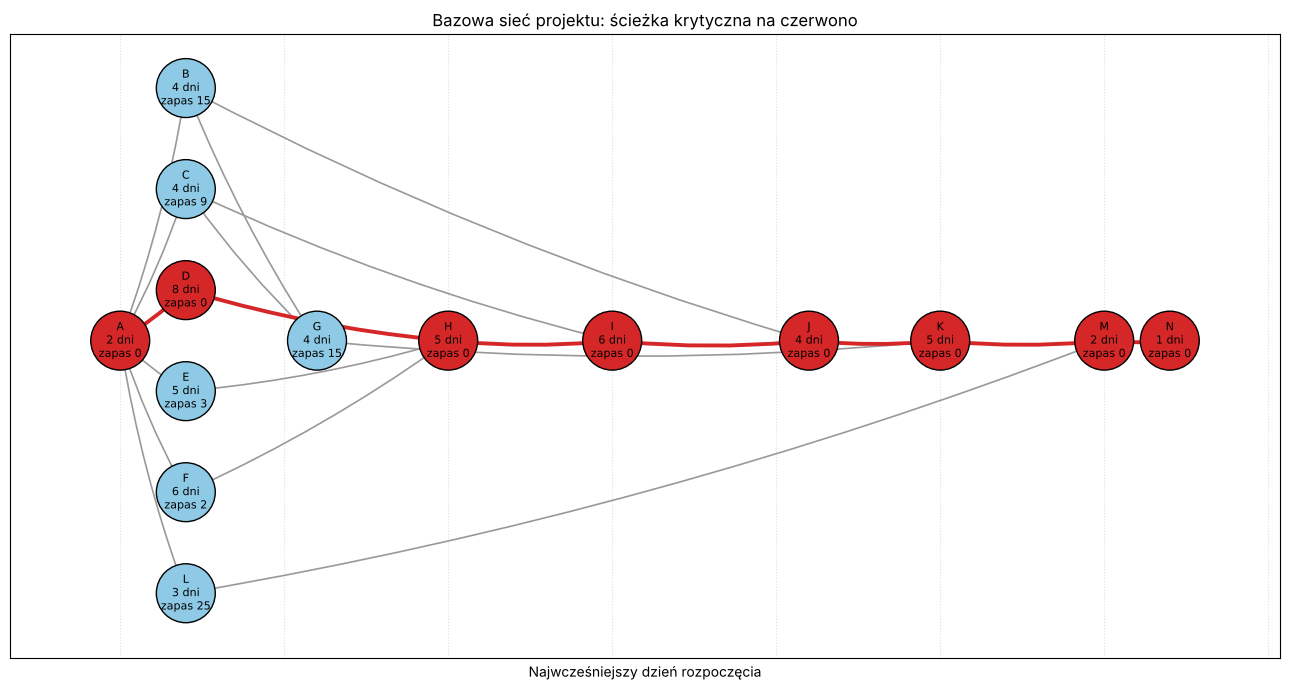

In [7]:
# Wyróżnienie łańcuchów pomaga połączyć zadania o zerowym zapasie w ścieżki.
plot_project_network(baseline_cpm, baseline_graph, title='Bazowa sieć projektu: ścieżka krytyczna na czerwono');


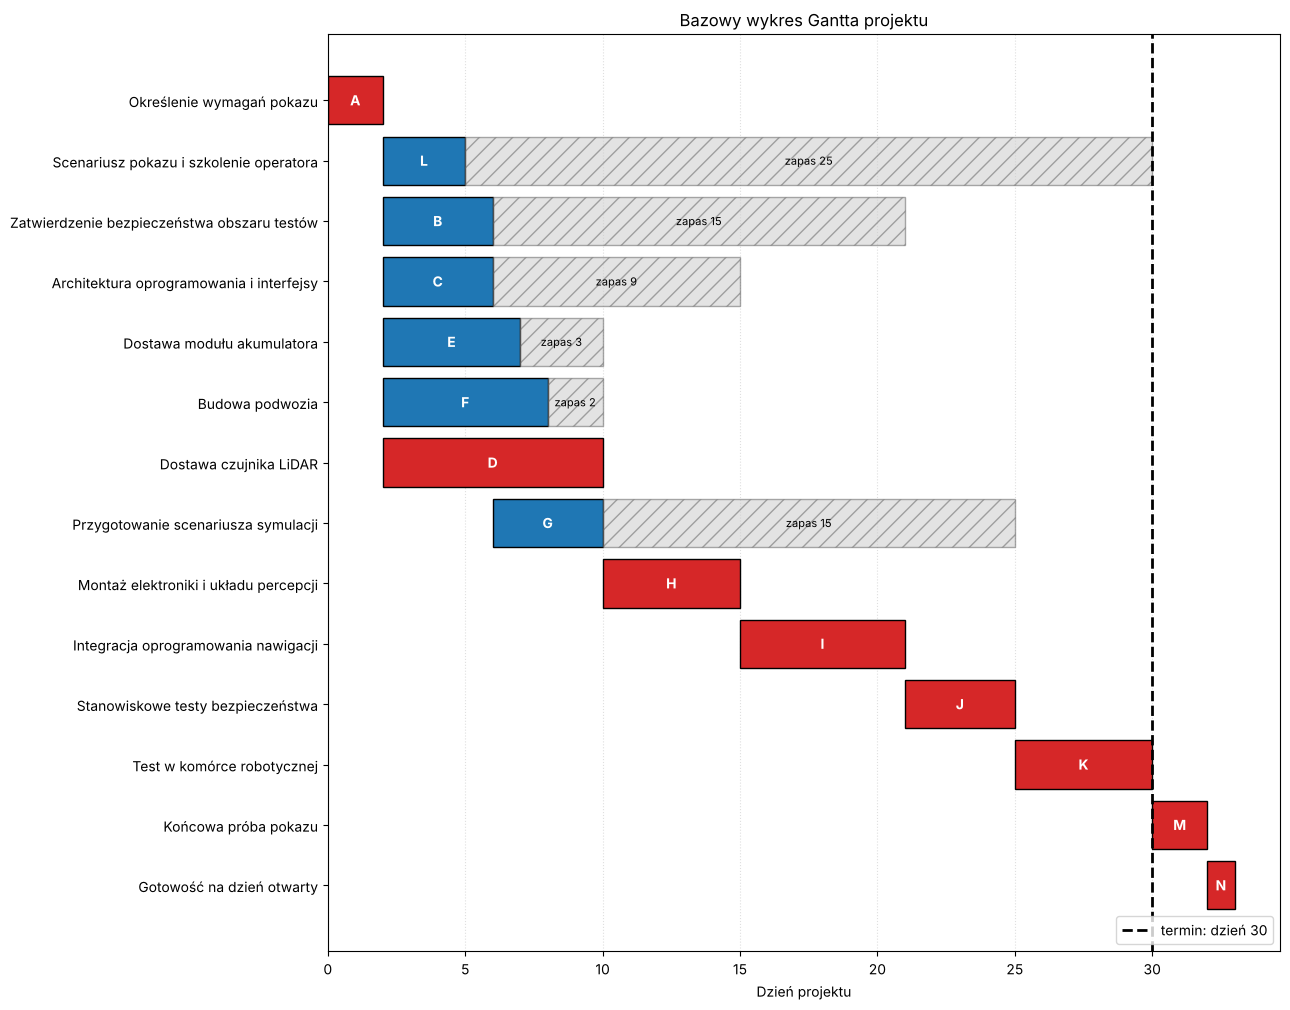

In [8]:
# Porównaj najwcześniejsze czasy z celem kierownictwa; wykres nie uwzględnia ograniczeń zasobowych.
plot_project_gantt(baseline_cpm, deadline=30, title='Bazowy wykres Gantta projektu');


### Zadanie 2 — odczytaj wykres Gantta

Kolorowy pasek przedstawia pracę, a szary kreskowany — zapas czasu. Odpowiedz na podstawie wykresu:

1. Które zadania mogą rozpocząć się bezpośrednio po A?
2. Które kończą się wcześnie, lecz nie wyznaczają końca projektu?
3. Czy opóźnienie L o 10 dni przesunie koniec projektu? Porównaj z zapasem L.
4. Czy opóźnienie D o 2 dni przesunie koniec projektu? Porównaj z zapasem D.
5. Które dwa lub trzy zapasy czasu warto przekazać kierownikowi projektu i dlaczego?

> **Rozwiązanie zadania 2.**
>
> 1. Bezpośrednio po A (od dnia 2) mogą zacząć się: **B, C, D, E, F i L** — wszystkie mają A jako jedynego poprzednika.
> 2. Wcześnie kończą się, ale nie wyznaczają końca projektu: **L** (koniec w dniu 5, zapas 25), **B** i **C** (koniec w 6, zapas 15 i 9), **G** (koniec w 10, zapas 15), a także dostawa akumulatora **E** (7, zapas 3) i podwozie **F** (8, zapas 2).
> 3. **Opóźnienie L o 10 dni nie przesunie końca projektu** — 10 < 25 dni zapasu. L kończyłoby się w dniu 15, a M i tak czeka na K do dnia 30.
> 4. **Opóźnienie D o 2 dni przesunie koniec o 2 dni** (na dzień 35). D jest na ścieżce krytycznej i ma zapas 0.
> 5. Kierownikowi przekazałbym przede wszystkim **małe zapasy na „bocznych” dostawach i budowie**: **F (podwozie) — 2 dni** i **E (akumulator) — 3 dni**. Po drobnym poślizgu te zadania same staną się krytyczne. Trzeba je monitorować razem z D, bo wszystkie trzy zbiegają się w H. Warto też podać **C — 9 dni**, bo zespół oprogramowania prowadzi również krytyczne I. Duże zapasy (L 25, B/G 15) można wykorzystać do przesunięcia ludzi, a nie trzeba ich pilnować.

## Warstwa decyzyjna 1: dwóch dystrybutorów

Dział zakupów otrzymał dwie niezależne oferty dostaw ekspresowych. Dotyczą różnych części:

- zadanie D — dostawa czujnika LiDAR,
- zadanie E — dostawa modułu akumulatora.

Standardowy czas dostawy znajduje się już w harmonogramie bazowym. Dostawa ekspresowa jest szybsza, a `extra_cost` oznacza dopłatę do opcji standardowej. Pomijamy bazowe ceny zakupów, ponieważ są takie same w każdym scenariuszu i nie wpływają na decyzję.

Kusząca reguła „kup każdą szybszą opcję” jest błędna. CPM podpowiada:

> Zapłać za przyspieszenie, gdy wpływa ono na ścieżkę, która jest lub może stać się krytyczna.

Pytamy więc nie tylko o dni dostawy, lecz także o zaoszczędzone dni projektu.

Stałe etykiety wariantów w tabelach pozostają angielskie: `standard suppliers` — dostawy standardowe, `express LiDAR` / `express LiDAR only` — ekspresowy LiDAR, `express battery` / `express battery only` — ekspresowy akumulator, `express both` — obie dostawy ekspresowe.

In [9]:
# Dni zaoszczędzone na dostawie są lokalną korzyścią; następny model sprawdza wpływ na cały projekt.
supplier_options = pd.DataFrame([
    {
        "component": 'Czujniki LiDAR',
        "task_id": "D",
        "standard_duration": 8,
        "express_duration": 5,
        "extra_cost": 2400,
        "comment": 'Specjalistyczny dystrybutor czujników z priorytetową wysyłką',
    },
    {
        "component": 'Moduły akumulatorów',
        "task_id": "E",
        "standard_duration": 5,
        "express_duration": 3,
        "extra_cost": 1200,
        "comment": 'Lokalny dystrybutor akumulatorów z wysyłką w tym samym tygodniu',
    },
])

supplier_options["delivery_days_saved"] = (
    supplier_options["standard_duration"] - supplier_options["express_duration"]
)
supplier_options["cost_per_delivery_day_saved"] = (
    supplier_options["extra_cost"] / supplier_options["delivery_days_saved"]
)

supplier_options


,component,task_id,standard_duration,express_duration,extra_cost,comment,delivery_days_saved,cost_per_delivery_day_saved
0,Czujniki LiDAR,D,8,5,2400,Specjalistyczny dystrybutor czujników z priory...,3,800.0
1,Moduły akumulatorów,E,5,3,1200,Lokalny dystrybutor akumulatorów z wysyłką w t...,2,600.0


### Funkcje dostaw: zmiany czasów → oszczędność czasu projektu

`apply_duration_changes(tasks, changes)` kopiuje dane i zastępuje tylko wskazane czasy deterministyczne. `evaluate_duration_scenario(tasks, label, changes, extra_cost)` ponownie oblicza CPM, porównuje zakończenie z `baseline_duration` i zwraca słownik podsumowania, tabelę CPM oraz graf. Koszty są dopłatami w PLN; wynik określa koszt zaoszczędzonego dnia **projektu**, a nie dnia dostawy.

In [10]:
# Oddziel scenariusze dostaw, aby ich zmiany nie kumulowały się w danych bazowych.
def apply_duration_changes(tasks, changes):
    """Kopiuje tabelę zadań i zastępuje wskazane czasy deterministyczne.

    tasks to DataFrame z `id` i liczbowym `duration` w dniach. changes
    przypisuje istniejącym ID nowe czasy w dniach; pusty słownik oznacza
    brak zmian. Zwraca kopię DataFrame z zastąpionymi czasami, zachowując
    zależności i oszacowania PERT. Zgłasza ValueError dla nieznanych ID.
    Korzysta z indeksowania pandas. Wywołujący podaje sensowne nieujemne
    czasy; późniejsze compute_cpm ocenia wpływ na projekt."""
    updated = tasks.copy(deep=True)
    for task_id, new_duration in changes.items():
        if task_id not in set(updated["id"]):
            raise ValueError(f"Nieznany identyfikator zadania: {task_id}")
        updated.loc[updated["id"] == task_id, "duration"] = new_duration
    return updated


def evaluate_duration_scenario(tasks, label, changes=None, extra_cost=0):
    """Porównuje deterministyczny wariant dostaw z zapisanym wariantem bazowym.

    tasks to DataFrame projektu używany przez compute_cpm; label jest nazwą
    scenariusza. changes to opcjonalny słownik ID→czas w dniach (None oznacza
    brak zmian), a extra_cost domyślnie 0 PLN dopłaty do zakupów standardowych.
    Stosuje zmiany, oblicza CPM i zwraca (summary_dict, cpm_table, graph).
    Podsumowanie zawiera czas, zaoszczędzone dni, dopłatę, PLN na zaoszczędzony
    dzień projektu (NaN przy braku oszczędności) i napis ścieżki krytycznej.
    Korzysta z globalnego baseline_duration oraz apply_duration_changes,
    compute_cpm i one_critical_path; nie wycenia bazowych podzespołów."""
    changes = changes or {}
    scenario_tasks = apply_duration_changes(tasks, changes)
    scenario_cpm, scenario_graph, scenario_duration = compute_cpm(scenario_tasks, duration_col="duration")
    # Porównaj oszczędność czasu całego projektu z wariantem bazowym, nie tylko czas dostawy.
    days_saved = baseline_duration - scenario_duration
    cost_per_project_day = extra_cost / days_saved if days_saved > 0 else np.nan
    summary = {
        "scenario": label,
        "project_duration": scenario_duration,
        "days_saved_vs_baseline": days_saved,
        "extra_cost": extra_cost,
        "cost_per_project_day_saved": cost_per_project_day,
        "critical_path": " -> ".join(one_critical_path(scenario_cpm, scenario_graph)),
    }
    return summary, scenario_cpm, scenario_graph


# Porównaj wszystkie opcje dostaw; jest ich na tyle mało, że można je jawnie wyliczyć.
supplier_scenarios = [
    ("standard suppliers", {}, 0),
    ("express LiDAR only", {"D": 5}, 2400),
    ("express battery only", {"E": 3}, 1200),
    ("express both", {"D": 5, "E": 3}, 3600),
]

supplier_results = []
for label, changes, cost in supplier_scenarios:
    summary, _, _ = evaluate_duration_scenario(project_tasks, label, changes, cost)
    supplier_results.append(summary)

supplier_results_table = pd.DataFrame(supplier_results)
supplier_results_table


,scenario,project_duration,days_saved_vs_baseline,extra_cost,cost_per_project_day_saved,critical_path
0,standard suppliers,33,0,0,NaN,A -> D -> H -> I -> J -> K -> M -> N
1,express LiDAR only,31,2,2400,1200.0,A -> F -> H -> I -> J -> K -> M -> N
2,express battery only,33,0,1200,NaN,A -> D -> H -> I -> J -> K -> M -> N
3,express both,31,2,3600,1800.0,A -> F -> H -> I -> J -> K -> M -> N


### Zadanie 3 — wybór dostawy

Korzystaj z obu tabel: `supplier_options` pokazuje skrócenie dostawy, a `supplier_results_table` — wpływ na cały projekt.

1. Która dostawa ekspresowa skraca projekt?
2. Która go nie skraca? Uzasadnij zapasem czasu lub ścieżką krytyczną.
3. Dlaczego dostawa LiDAR-u szybsza o 3 dni nie musi oszczędzać 3 dni projektu?
4. Które zadanie lub ścieżka zyskuje znaczenie po przyspieszeniu LiDAR-u?
5. Czy zapłacisz za obie dostawy ekspresowe? Porównaj oszczędność czasu projektu i koszt, a nie tylko czas dostawy.

In [11]:
# Zadanie 3: jak zmieniają się zapasy po ekspresowym LiDAR-ze?
_, lidar_cpm, lidar_graph = evaluate_duration_scenario(project_tasks, "express LiDAR only", {"D": 5}, 2400)
display(lidar_cpm.loc[lidar_cpm.id.isin(["D", "E", "F", "H"]), ["id", "task", "duration", "ES", "EF", "slack", "critical"]])

,id,task,duration,ES,EF,slack,critical
3,D,Dostawa czujnika LiDAR,5,2,7,1,False
4,E,Dostawa modułu akumulatora,5,2,7,1,False
5,F,Budowa podwozia,6,2,8,0,True
8,H,Montaż elektroniki i układu percepcji,5,8,13,0,True


> **Rozwiązanie zadania 3.**
>
> 1. **Skraca projekt tylko ekspresowy LiDAR**: 33 → **31 dni** (2 dni) za 2400 PLN, czyli 1200 PLN za zaoszczędzony dzień projektu.
> 2. **Ekspresowy akumulator nie skraca projektu** (nadal 33 dni). Dostawa E ma 3 dni zapasu i nie leży na ścieżce krytycznej. Skrócenie jej o 2 dni tylko zwiększa ten zapas do 5, a H dalej czeka na LiDAR (dzień 10).
> 3. LiDAR szybszy o 3 dni (EF 10 → 7) **oszczędza tylko 2 dni**, bo H czeka na **wszystkich** poprzedników. Po zmianie najpóźniej kończy się podwozie F (dzień 8), więc H zaczyna w dniu 8, a nie 7. Trzeci dzień przyspieszenia „ginie” w zapasie, który powstaje przy D.
> 4. Znaczenie zyskuje **budowa podwozia F**: zapas spada z 2 do **0**, a ścieżka krytyczna to teraz **A → F → H → I → J → K → M → N**. Akumulator E ma już tylko 1 dzień zapasu.
> 5. **Nie zapłacę za obie dostawy ekspresowe.** „Express both” daje te same 31 dni co sam LiDAR, ale kosztuje 3600 zamiast 2400 PLN — dodatkowe 1200 PLN za akumulator nie oszczędza żadnego dnia projektu, bo blokuje F, a nie E.

## Warstwa decyzyjna 2: skracanie czasu zadań

Skracanie czasu zadań (*crashing*) oznacza dodatkowy wydatek, nadgodziny lub dodatkowych pracowników w zamian za krótszy czas wykonania.

Nie polega na przyspieszaniu wszystkich długich zadań. Długie zadanie niekrytyczne może mieć taki zapas czasu, że jego skrócenie nie zmieni końca projektu.

In [12]:
# Limity i dopłaty w PLN/dzień określają dozwolone warianty skracania zadań.
crash_options = pd.DataFrame([
    {
        "task_id": "F",
        "task": 'Budowa podwozia',
        "max_reduction": 2,
        "cost_per_day": 900,
        "note": 'Dodaj drugiego technika i użyj gotowych wyciętych płyt montażowych',
    },
    {
        "task_id": "H",
        "task": 'Montaż elektroniki i układu percepcji',
        "max_reduction": 2,
        "cost_per_day": 1400,
        "note": 'Nadgodziny zespołu integracji',
    },
    {
        "task_id": "I",
        "task": 'Integracja oprogramowania nawigacji',
        "max_reduction": 3,
        "cost_per_day": 1600,
        "note": 'Zaangażuj doświadczonego programistę z innego projektu',
    },
    {
        "task_id": "J",
        "task": 'Stanowiskowe testy bezpieczeństwa',
        "max_reduction": 1,
        "cost_per_day": 1700,
        "note": 'Weekendowy przegląd bezpieczeństwa',
    },
    {
        "task_id": "K",
        "task": 'Test w komórce robotycznej',
        "max_reduction": 2,
        "cost_per_day": 2000,
        "note": 'Zarezerwuj wieczorne testy i dodatkowego operatora',
    },
])

crash_options


,task_id,task,max_reduction,cost_per_day,note
0,F,Budowa podwozia,2,900,Dodaj drugiego technika i użyj gotowych wycięt...
1,H,Montaż elektroniki i układu percepcji,2,1400,Nadgodziny zespołu integracji
2,I,Integracja oprogramowania nawigacji,3,1600,Zaangażuj doświadczonego programistę z innego ...
3,J,Stanowiskowe testy bezpieczeństwa,1,1700,Weekendowy przegląd bezpieczeństwa
4,K,Test w komórce robotycznej,2,2000,Zarezerwuj wieczorne testy i dodatkowego opera...


### Funkcje skracania: dopuszczalne redukcje → warianty planu

`apply_crash_plan(tasks, reductions)` odejmuje wskazane dni na kopii tabeli. `evaluate_full_plan` najpierw zastępuje czasy dostaw, następnie stosuje redukcje i zwraca zmienione zadania, tabelę CPM, graf oraz dzień zakończenia. `enumerate_supplier_and_crash_plans(tasks, crash_options, deadline)` łączy cztery wbudowane opcje dostaw z każdą dozwoloną całkowitą redukcją dni i zwraca nieposortowany DataFrame planów z kosztami oraz informacją o spełnieniu terminu. Plan wybierasz, filtrując i porządkując tę tabelę.

In [13]:
# Oceń każdy wariant według jego nowej ścieżki; zadania bazowo krytyczne mogą przestać takie być.
def apply_crash_plan(tasks, reductions):
    """Kopiuje tabelę zadań i odejmuje wskazane redukcje czasu.

    tasks ma `id` i liczbowe `duration`. reductions przypisuje istniejącym
    ID nieujemne redukcje w dniach; enumeracja podaje całkowite liczby dni.
    Zwraca kopię tabeli z czasami ograniczonymi od dołu do zera, bez zmiany
    innych kolumn. Zgłasza ValueError dla ujemnych redukcji lub nieznanych ID.
    Korzysta z pandas; wywołujący pilnuje limitów i kosztów crash_options.
    Oszacowania PERT pozostają bez zmian — nie są automatycznie skracane."""
    updated = tasks.copy(deep=True)
    base_duration = dict(zip(updated["id"], updated["duration"]))
    for task_id, reduction in reductions.items():
        if reduction < 0:
            raise ValueError('Redukcja czasu nie może być ujemna.')
        if task_id not in base_duration:
            raise ValueError(f"Nieznany identyfikator zadania: {task_id}")
        updated.loc[updated["id"] == task_id, "duration"] = max(0, base_duration[task_id] - reduction)
    return updated


def evaluate_full_plan(tasks, supplier_changes=None, crash_reductions=None):
    """Stosuje zmiany dostaw, następnie skracanie zadań i ponownie oblicza CPM.

    tasks to DataFrame z `id`, `duration` w dniach i `predecessors`.
    supplier_changes przypisuje ID nowe czasy; crash_reductions przypisuje
    ID redukcje w dniach. Oba domyślnie None, czyli brak zmian.
    Zwraca (updated_tasks, cpm_table, graph, duration_days). Korzysta z
    apply_duration_changes, apply_crash_plan i compute_cpm; koszt oblicza
    wywołujący, a kolumny PERT pozostają bez zmian."""
    supplier_changes = supplier_changes or {}
    crash_reductions = crash_reductions or {}
    # Najpierw zmień czas dostawy, następnie odejmij redukcję od uzyskanego czasu.
    updated = apply_duration_changes(tasks, supplier_changes)
    updated = apply_crash_plan(updated, crash_reductions)
    cpm_table, graph, duration = compute_cpm(updated, duration_col="duration")
    return updated, cpm_table, graph, duration


def enumerate_supplier_and_crash_plans(tasks, crash_options, deadline=30):
    """Ocenia wbudowane warianty dostaw i wszystkie dozwolone całodniowe redukcje.

    tasks to DataFrame projektu z zadaniami dostaw D/E. crash_options to
    DataFrame z `task_id`, `max_reduction` w całych dniach i `cost_per_day`
    w PLN/dzień. deadline domyślnie oznacza dzień projektu 30.
    Wylicza cztery ustalone warianty dostaw oraz każdą całkowitą redukcję
    od zera do limitu; oblicza CPM i dodaje dopłaty za dostawy i skracanie.
    Zwraca nieposortowany DataFrame z supplier_choice, crash_reductions,
    project_duration, days_saved_vs_baseline, total_extra_cost, meets_deadline
    i critical_path. Korzysta z globalnego baseline_duration, product
    z itertools, evaluate_full_plan i one_critical_path. Nie wybiera planu
    automatycznie i nie odczytuje osobnej tabeli ofert dostawców."""
    supplier_cases = [
        ("standard suppliers", {}, 0),
        ("express LiDAR", {"D": 5}, 2400),
        ("express battery", {"E": 3}, 1200),
        ("express both", {"D": 5, "E": 3}, 3600),
    ]

    # Zakresy całkowite zawierają brak redukcji i każdą dozwoloną liczbę dni do limitu.
    crash_ranges = [range(int(row.max_reduction) + 1) for row in crash_options.itertuples(index=False)]
    crash_task_ids = list(crash_options["task_id"])
    cost_per_day = dict(zip(crash_options["task_id"], crash_options["cost_per_day"]))

    rows = []
    for supplier_label, supplier_changes, supplier_cost in supplier_cases:
        for values in product(*crash_ranges):
            reductions = dict(zip(crash_task_ids, values))
            _, cpm_table, graph, duration = evaluate_full_plan(
                tasks,
                supplier_changes=supplier_changes,
                crash_reductions=reductions,
            )
            # Uwzględnij tylko dopłaty za dostawy i skracanie, pomijając w rankingu bazowe ceny zakupów.
            crash_cost = sum(reductions[task_id] * cost_per_day[task_id] for task_id in crash_task_ids)
            total_cost = supplier_cost + crash_cost
            rows.append({
                "supplier_choice": supplier_label,
                "crash_reductions": reductions,
                "project_duration": duration,
                "days_saved_vs_baseline": baseline_duration - duration,
                "total_extra_cost": total_cost,
                "meets_deadline": duration <= deadline,
                "critical_path": " -> ".join(one_critical_path(cpm_table, graph)),
            })

    # Zwróć kolejność wyliczania; sposób filtrowania i sortowania wybierasz w zadaniu.
    return pd.DataFrame(rows)


In [14]:
# Najpierw wygeneruj warianty; samodzielnie odfiltruj je według terminu i uporządkuj według kosztu.
deadline = 30
plans = enumerate_supplier_and_crash_plans(project_tasks, crash_options, deadline=deadline)

print(f"Wygenerowano {len(plans)} wariantów planu. Pierwsze wiersze nie są rankingiem.")
plans[[
    "supplier_choice", "crash_reductions", "project_duration", "total_extra_cost", "meets_deadline"
]].head(8)


Wygenerowano 864 wariantów planu. Pierwsze wiersze nie są rankingiem.


,supplier_choice,crash_reductions,project_duration,total_extra_cost,meets_deadline
0,standard suppliers,"{'F': 0, 'H': 0, 'I': 0, 'J': 0, 'K': 0}",33,0,False
1,standard suppliers,"{'F': 0, 'H': 0, 'I': 0, 'J': 0, 'K': 1}",32,2000,False
2,standard suppliers,"{'F': 0, 'H': 0, 'I': 0, 'J': 0, 'K': 2}",31,4000,False
3,standard suppliers,"{'F': 0, 'H': 0, 'I': 0, 'J': 1, 'K': 0}",32,1700,False
4,standard suppliers,"{'F': 0, 'H': 0, 'I': 0, 'J': 1, 'K': 1}",31,3700,False
5,standard suppliers,"{'F': 0, 'H': 0, 'I': 0, 'J': 1, 'K': 2}",30,5700,True
6,standard suppliers,"{'F': 0, 'H': 0, 'I': 1, 'J': 0, 'K': 0}",32,1600,False
7,standard suppliers,"{'F': 0, 'H': 0, 'I': 1, 'J': 0, 'K': 1}",31,3600,False


### Zadanie 4 — wybierz plan

Pokaz ma być gotowy w dniu 30. Tabela `plans` zawiera wszystkie kombinacje dostaw i całkowitych redukcji czasu z `crash_options`.

1. Odfiltruj wiersze, gdzie `meets_deadline` jest `True`, i posortuj je według `total_extra_cost`.
2. Znajdź najtańszy plan spełniający termin.
3. Dlaczego jest tańszy niż skracanie tylko oczywistych zadań krytycznych z wariantu bazowego? Wskazówka: po zmianie ścieżka krytyczna może się przesunąć.
4. Wpisz wybrane zmiany dostaw i redukcje czasu w następnej komórce.
5. Po zastosowaniu planu narysuj ponownie wykres Gantta.
6. Wskaż nową ścieżkę krytyczną. Czy różni się od bazowej?

In [15]:
# Zadanie 4: plany spełniające termin, posortowane według łącznej dopłaty.
feasible_plans = (plans[plans["meets_deadline"]]
                  .sort_values(["total_extra_cost", "project_duration"])
                  .reset_index(drop=True))
print(f"Plany spełniające termin dnia {deadline}: {len(feasible_plans)} z {len(plans)}")
display(feasible_plans[["supplier_choice", "crash_reductions", "project_duration",
                        "total_extra_cost", "critical_path"]].head(8))

# Dla porównania: najtańsze skracanie tylko oczywistych zadań krytycznych, bez zmiany dostaw.
obvious = plans[(plans.supplier_choice == "standard suppliers") & plans.meets_deadline
                & plans.crash_reductions.apply(lambda r: r["F"] == 0)]
print("Najtańszy plan tylko ze skracaniem H/I/J/K (dostawy standardowe):")
display(obvious.sort_values("total_extra_cost")[["crash_reductions", "project_duration", "total_extra_cost"]].head(3))

Plany spełniające termin dnia 30: 778 z 864


,supplier_choice,crash_reductions,project_duration,total_extra_cost,critical_path
0,express LiDAR,"{'F': 1, 'H': 0, 'I': 0, 'J': 0, 'K': 0}",30,3300,A -> D -> H -> I -> J -> K -> M -> N
1,express LiDAR,"{'F': 0, 'H': 1, 'I': 0, 'J': 0, 'K': 0}",30,3800,A -> F -> H -> I -> J -> K -> M -> N
2,express LiDAR,"{'F': 0, 'H': 0, 'I': 1, 'J': 0, 'K': 0}",30,4000,A -> F -> H -> I -> J -> K -> M -> N
3,express LiDAR,"{'F': 0, 'H': 0, 'I': 0, 'J': 1, 'K': 0}",30,4100,A -> F -> H -> I -> J -> K -> M -> N
4,express LiDAR,"{'F': 2, 'H': 0, 'I': 0, 'J': 0, 'K': 0}",30,4200,A -> D -> H -> I -> J -> K -> M -> N
5,standard suppliers,"{'F': 0, 'H': 2, 'I': 1, 'J': 0, 'K': 0}",30,4400,A -> D -> H -> I -> J -> K -> M -> N
6,express LiDAR,"{'F': 0, 'H': 0, 'I': 0, 'J': 0, 'K': 1}",30,4400,A -> F -> H -> I -> J -> K -> M -> N
7,standard suppliers,"{'F': 0, 'H': 2, 'I': 0, 'J': 1, 'K': 0}",30,4500,A -> D -> H -> I -> J -> K -> M -> N


Najtańszy plan tylko ze skracaniem H/I/J/K (dostawy standardowe):


,crash_reductions,project_duration,total_extra_cost
54,"{'F': 0, 'H': 2, 'I': 1, 'J': 0, 'K': 0}",30,4400
51,"{'F': 0, 'H': 2, 'I': 0, 'J': 1, 'K': 0}",30,4500
36,"{'F': 0, 'H': 1, 'I': 2, 'J': 0, 'K': 0}",30,4600


> **Rozwiązanie zadania 4 (punkty 1–3).**
>
> - Termin dnia 30 spełnia **778 z 864** wariantów. **Najtańszy** to **ekspresowy LiDAR + skrócenie budowy podwozia F o 1 dzień**: projekt trwa **30 dni**, dopłata **3300 PLN** (2400 + 900).
> - Skracanie tylko „oczywistych” zadań krytycznych wariantu bazowego (H, I, J, K) przy standardowych dostawach kosztuje co najmniej **4400 PLN** (H o 2 dni + I o 1 dzień). Wybrany plan jest **o 1100 PLN tańszy**, bo wykorzystuje przesuwanie się ścieżki krytycznej. Ekspresowy LiDAR daje 2 dni po 1200 PLN/dzień, taniej niż skracanie H (1400), I (1600), J (1700) czy K (2000). Po tej zmianie krytyczne staje się F, którego skrócenie kosztuje tylko 900 PLN/dzień. W wariancie bazowym skracanie F nie dawało nic (F miało 2 dni zapasu).
>
> Plan wpisałem w komórce poniżej (`selected_supplier_changes = {"D": 5}`, `selected_crash_reductions = {"F": 1}`).

In [16]:
# Wybrane słowniki tworzą nowy harmonogram; wariant bazowy pozostaje dostępny do porównania.
# DO ZROBIENIA: wpisz do słowników plan wybrany w zadaniu 4.
# Najpierw pozostaw puste słowniki wariantu bazowego, potem zmień je i uruchom ponownie.
# Mój wybór (zadanie 4): ekspresowa dostawa LiDAR-u + skrócenie budowy podwozia F o 1 dzień.
selected_supplier_changes = {"D": 5}
selected_crash_reductions = {"F": 1}

selected_tasks, selected_cpm, selected_graph, selected_duration = evaluate_full_plan(
    project_tasks,
    supplier_changes=selected_supplier_changes,
    crash_reductions=selected_crash_reductions,
)

print(f"Czas wybranego planu: {selected_duration:.0f} dni")
print(f"Spełnia termin w dniu {deadline}: {selected_duration <= deadline}")

selected_cpm[["id", "task", "duration", "ES", "EF", "LS", "LF", "slack"]]


Czas wybranego planu: 30 dni
Spełnia termin w dniu 30: True


,id,task,duration,ES,EF,LS,LF,slack
0,A,Określenie wymagań pokazu,2,0,2,0,2,0
1,B,Zatwierdzenie bezpieczeństwa obszaru testów,4,2,6,14,18,12
2,C,Architektura oprogramowania i interfejsy,4,2,6,8,12,6
3,D,Dostawa czujnika LiDAR,5,2,7,2,7,0
4,E,Dostawa modułu akumulatora,5,2,7,2,7,0
5,F,Budowa podwozia,5,2,7,2,7,0
6,L,Scenariusz pokazu i szkolenie operatora,3,2,5,24,27,22
7,G,Przygotowanie scenariusza symulacji,4,6,10,18,22,12
8,H,Montaż elektroniki i układu percepcji,5,7,12,7,12,0
9,I,Integracja oprogramowania nawigacji,6,12,18,12,18,0


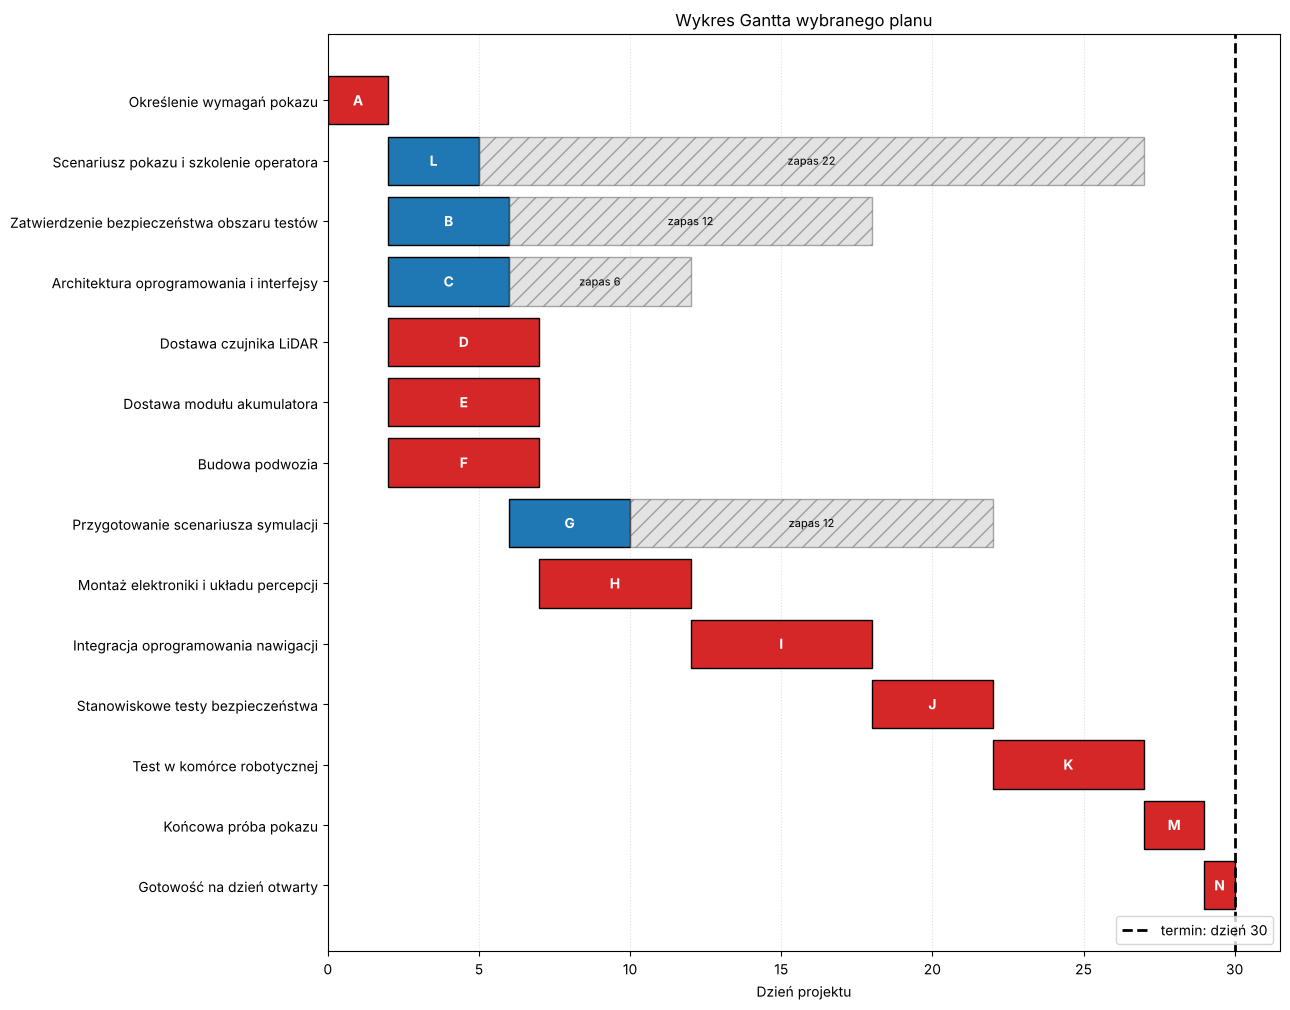

In [17]:
# Narysuj tę samą tabelę CPM, z której odczytujesz czas i zapas czasu wybranego planu.
plot_project_gantt(selected_cpm, deadline=deadline, title='Wykres Gantta wybranego planu');


Zadania krytyczne po zmianach: ['A', 'D', 'E', 'F', 'H', 'I', 'J', 'K', 'M', 'N']
Krawędzie krytyczne: [('A', 'D'), ('A', 'E'), ('A', 'F'), ('D', 'H'), ('E', 'H'), ('F', 'H'), ('H', 'I'), ('I', 'J'), ('J', 'K'), ('K', 'M'), ('M', 'N')]


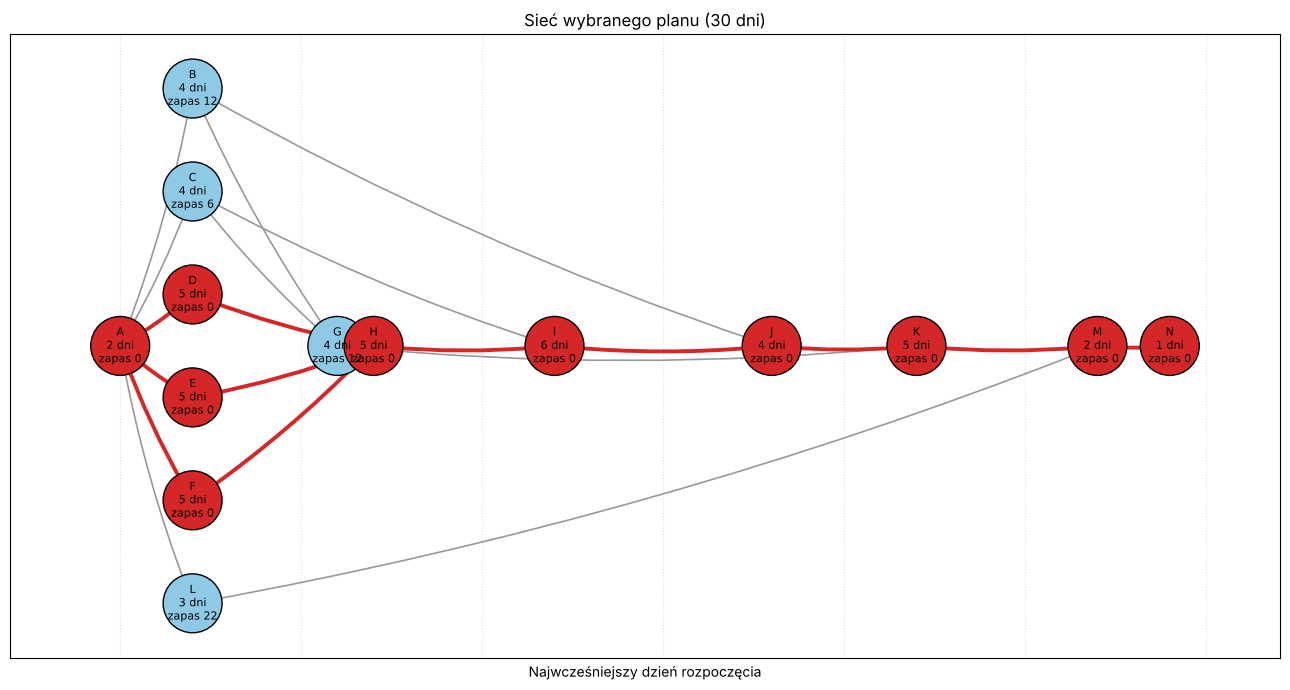

In [18]:
# Zadanie 4 (punkt 6): nowa ścieżka krytyczna wybranego planu.
print("Zadania krytyczne po zmianach:", list(selected_cpm.loc[selected_cpm.critical, "id"]))
print("Krawędzie krytyczne:", critical_edges(selected_cpm, selected_graph))
plot_project_network(selected_cpm, selected_graph, title="Sieć wybranego planu (30 dni)");

> **Nowa ścieżka krytyczna (punkt 6):** po zmianach D (5 dni), E (5 dni) i F (5 dni) kończą się **jednocześnie w dniu 7**, więc wszystkie trzy mają zerowy zapas. Są **trzy równoległe łańcuchy krytyczne**: **A → D / E / F → H → I → J → K → M → N** (30 dni). To różni się od wariantu bazowego, gdzie krytyczny był tylko LiDAR (D). Plan jest teraz „napięty”: poślizg **którejkolwiek** z trzech dostaw/prac (LiDAR, akumulator, podwozie) przesuwa projekt. Wykres Gantta powyżej nie ma już zapasu przy E i F.

## PERT: niepewne czasy i ryzyko niedotrzymania terminu

CPM zakłada ustalone czasy. PERT zastępuje pojedynczy czas trzema oszacowaniami:

$$
E = \frac{a + 4m + b}{6}
$$

$$
\sigma^2 = \left(\frac{b-a}{6}\right)^2
$$

`E` to oczekiwany czas zadania, a `sigma^2` — jego wariancja. Typowe przybliżenie projektu sumuje wariancje wzdłuż oczekiwanej ścieżki krytycznej i opisuje czas zakończenia rozkładem normalnym.

To przydatne, lecz ma ograniczenie: rzeczywiste czasy mogą spowodować zmianę ścieżki krytycznej.

### Funkcje PERT: trzy oszacowania → przybliżone prawdopodobieństwo

`add_pert_columns(tasks)` zwraca kopię tabeli ze średnimi i wariancjami zadań. `pert_summary(tasks, deadline)` wykonuje CPM dla średnich, sumuje wariancje na jednej oczekiwanej ścieżce krytycznej i wykorzystuje `normal_cdf(z)` do przybliżenia prawdopodobieństwa zakończenia przed terminem. Zwraca tabelę CPM, graf i słownik podsumowania. Czasy są w dniach, wariancje w dniach kwadratowych, a prawdopodobieństwo nie ma jednostki.

In [19]:
# Oddziel niepewność zadań, czasy ścieżki i prawdopodobieństwo terminu, aby pokazać przybliżenie.
def add_pert_columns(tasks):
    """Kopiuje zadania i oblicza oczekiwane czasy oraz wariancje PERT.

    tasks to DataFrame z liczbowymi `a`, `m`, `b` w dniach; wywołujący
    powinien zapewnić czas optymistyczny <= najbardziej prawdopodobny
    <= pesymistyczny. Zwraca kopię z expected_duration w dniach i variance
    w dniach kwadratowych, zachowując czasy deterministyczne i inne kolumny.
    Korzysta z arytmetyki pandas; nie losuje harmonogramów ani nie sprawdza
    poprawności trzech oszacowań."""
    result = tasks.copy(deep=True)
    result["expected_duration"] = (result["a"] + 4 * result["m"] + result["b"]) / 6
    result["variance"] = ((result["b"] - result["a"]) / 6) ** 2
    return result


def normal_cdf(z):
    """Oblicza dystrybuantę standardowego rozkładu normalnego dla jednego z.

    z to skalarna liczba standaryzowana, bez jednostki. Zwraca skalarne
    prawdopodobieństwo P(Z <= z), korzystając z erf i sqrt z math.
    Służy przybliżeniu normalnemu PERT; nie modeluje zadań projektu
    ani nie wybiera terminu."""
    return 0.5 * (1 + erf(z / sqrt(2)))


def pert_summary(tasks, deadline):
    """Przybliża prawdopodobieństwo spełnienia terminu na jednej oczekiwanej ścieżce.

    tasks to DataFrame projektu z `id`, `predecessors` oraz oszacowaniami
    PERT `a`, `m`, `b` w dniach. deadline to liczbowy dzień projektu.
    Dodaje expected_duration/variance, oblicza CPM dla średnich, wybiera
    jedną ścieżkę krytyczną i sumuje jej wariancje. Zwraca (cpm_table, graph,
    summary_dict) z polami deadline, expected_project_duration, critical_path,
    critical_path_variance (dni kwadratowe), critical_path_std_dev (dni),
    z_value i approx_probability_finish_by_deadline (0..1).
    Wywołuje add_pert_columns, compute_cpm, one_critical_path i normal_cdf;
    zakłada niezależne czasy na ścieżce i pomija przejście na inną ścieżkę.
    Zerowa wariancja daje deterministyczne porównanie z terminem."""
    # CPM dla czasów oczekiwanych wyznacza ścieżkę przyjętą w tym przybliżeniu prawdopodobieństwa.
    pert_tasks = add_pert_columns(tasks)
    cpm_table, graph, expected_duration = compute_cpm(pert_tasks, duration_col="expected_duration")
    path = one_critical_path(cpm_table, graph)

    metrics = cpm_table.set_index("id")
    # Przybliżenie PERT: sumuj wariancje tylko na oczekiwanej ścieżce krytycznej.
    critical_path_variance = metrics.loc[path, "variance"].sum()
    critical_path_std = sqrt(critical_path_variance)

    # Unikaj dzielenia przez zero, gdy wszystkie oszacowania na ścieżce są deterministyczne.
    if critical_path_std > 0:
        z = (deadline - expected_duration) / critical_path_std
        probability = normal_cdf(z)
    else:
        z = np.inf if deadline >= expected_duration else -np.inf
        probability = float(deadline >= expected_duration)

    summary = {
        "deadline": deadline,
        "expected_project_duration": expected_duration,
        "critical_path": " -> ".join(path),
        "critical_path_variance": critical_path_variance,
        "critical_path_std_dev": critical_path_std,
        "z_value": z,
        "approx_probability_finish_by_deadline": probability,
    }
    return cpm_table, graph, summary


In [20]:
# Przyjmij termin oceny ryzyka niezależny od celu skrócenia planu deterministycznego.
risk_deadline = 36
pert_cpm, pert_graph, pert_stats = pert_summary(project_tasks, deadline=risk_deadline)

# Najpierw obejrzyj tabelę PERT poszczególnych zadań w następnej komórce.
# Po zapisaniu własnego oszacowania odkomentuj ostatni wiersz, aby sprawdzić podsumowanie.
pert_stats_for_check = pd.DataFrame([pert_stats])
# pert_stats_for_check


In [21]:
# Obejrzyj średnie i wariancje zadań przed interpretacją prawdopodobieństwa dla projektu.
pert_cpm[[
    "id", "task", "a", "m", "b", "expected_duration", "variance", "ES", "EF", "slack"
]]


,id,task,a,m,b,expected_duration,variance,ES,EF,slack
0,A,Określenie wymagań pokazu,1,2,3,2.000000,0.111111,0.000000,2.000000,1.776357e-15
1,B,Zatwierdzenie bezpieczeństwa obszaru testów,3,4,7,4.333333,0.444444,2.000000,6.333333,1.583333e+01
2,C,Architektura oprogramowania i interfejsy,3,4,7,4.333333,0.444444,2.000000,6.333333,9.500000e+00
3,D,Dostawa czujnika LiDAR,5,8,13,8.333333,1.777778,2.000000,10.333333,1.776357e-15
4,E,Dostawa modułu akumulatora,3,5,9,5.333333,1.000000,2.000000,7.333333,3.000000e+00
5,F,Budowa podwozia,4,6,9,6.166667,0.694444,2.000000,8.166667,2.166667e+00
6,L,Scenariusz pokazu i szkolenie operatora,2,3,4,3.000000,0.111111,2.000000,5.000000,2.733333e+01
7,G,Przygotowanie scenariusza symulacji,3,4,6,4.166667,0.250000,6.333333,10.500000,1.616667e+01
8,H,Montaż elektroniki i układu percepcji,4,5,9,5.500000,0.694444,10.333333,15.833333,1.776357e-15
9,I,Integracja oprogramowania nawigacji,4,6,10,6.333333,1.000000,15.833333,22.166667,1.776357e-15


### Zadanie 5 — interpretacja PERT

Najpierw obejrzyj tabelę zadań PERT. Gdy chcesz sprawdzić prawdopodobieństwo spełnienia terminu, wyświetl `pert_stats_for_check` z wcześniejszej komórki.

1. Które zadania mają największą niepewność? Sprawdź wariancję.
2. Które niepewne zadania należą do ścieżki krytycznej PERT? Użyj zerowego zapasu czasu i kolejności.
3. Jakie jest przybliżone prawdopodobieństwo ukończenia przed terminem przyjętym do oceny ryzyka?
4. Dlaczego wynik jest przybliżeniem, a nie gwarancją?

In [22]:
# Zadanie 5: podsumowanie PERT (odkomentowany odpowiednik pert_stats_for_check) i ranking niepewności.
display(pert_stats_for_check.T)
display(pert_cpm[["id", "task", "variance", "slack"]].sort_values("variance", ascending=False).head(6))

,0
deadline,36
expected_project_duration,35.666667
critical_path,A -> D -> H -> I -> J -> K -> M -> N
critical_path_variance,6.333333
critical_path_std_dev,2.516611
z_value,0.132453
approx_probability_finish_by_deadline,0.552687


,id,task,variance,slack
3,D,Dostawa czujnika LiDAR,1.777778,1.776357e-15
11,K,Test w komórce robotycznej,1.777778,0.000000e+00
9,I,Integracja oprogramowania nawigacji,1.000000,1.776357e-15
4,E,Dostawa modułu akumulatora,1.000000,3.000000e+00
5,F,Budowa podwozia,0.694444,2.166667e+00
10,J,Stanowiskowe testy bezpieczeństwa,0.694444,0.000000e+00


> **Rozwiązanie zadania 5.**
>
> 1. **Największą niepewność** mają: **D — dostawa LiDAR-u** i **K — test w komórce robotycznej** (wariancja 1,78 dnia², σ ≈ 1,33 dnia), dalej **E — akumulator** i **I — integracja nawigacji** (1,00 dnia²).
> 2. Ścieżka krytyczna PERT (czasy oczekiwane) to ta sama **A → D → H → I → J → K → M → N**. Leżą na niej najbardziej niepewne zadania **D, K i I**, a także H i J. E (najbardziej niepewna dostawa poza ścieżką) ma 3 dni zapasu.
> 3. Oczekiwany czas projektu to **35,67 dnia**, σ ścieżki ≈ **2,52 dnia**, z = (36 − 35,67) / 2,52 ≈ 0,13, więc prawdopodobieństwo ukończenia do dnia 36 wynosi **≈ 55%** — niewiele więcej niż rzut monetą.
> 4. To **przybliżenie**, bo zakłada: niezależność czasów zadań, rozkład normalny sumy (przy 8 zadaniach o skośnych rozkładach to tylko aproksymacja) i — najważniejsze — że **koniec zawsze wyznacza ta sama ścieżka**. Gdy LiDAR przyjdzie wcześnie, a podwozie się opóźni, krytyczna staje się inna ścieżka (F ma tylko ~2 dni zapasu), a wzór PERT tego nie widzi. Do tego same oszacowania a, m, b są subiektywne.

## Warstwa decyzyjna 3: dodanie zadania zmniejszającego ryzyko

Zespół integracji proponuje **jednodniowy przegląd interfejsów czujników** przed montażem elektroniki.

Wygląda jak dodatkowa praca, ponieważ dodaje widoczne zadanie do sieci. Ma jednak zapobiegać błędom połączeń i interfejsów oraz zwiększać przewidywalność montażu.

Założenia ćwiczenia:

- Dodaj zadanie `R`: przegląd interfejsów czujników, 1 dzień, po D, E i F.
- Zmień H tak, aby zależało od R zamiast bezpośrednio od D, E i F.
- Skróć deterministyczny czas H z 5 do 4 dni.
- Zmień oszacowania PERT zadania H z `(a=4, m=5, b=9)` na `(a=3, m=4, b=5)`.

To inny mechanizm niż zwykłe skracanie czasu zadań. Przegląd może zmniejszyć zarówno czas oczekiwany, jak i niepewność późniejszej pracy, mimo dodania nowego zadania do harmonogramu.

Etykiety porównania pozostają kluczami danych: `original` — projekt pierwotny, `with sensor interface review` — projekt z przeglądem interfejsów.

### Funkcja przeglądu: zmienione zależności → dane porównania

`add_sensor_interface_review(tasks)` kopiuje projekt, dodaje jednodniowe R po D/E/F, uzależnia H od R i zastępuje jego czasy deterministyczne/PERT. Zwraca zmienioną tabelę. Następne wywołania przekazują ją do CPM i PERT, tworząc `risk_comparison`; sama funkcja nie rozstrzyga, czy warto zapłacić za przegląd.

In [23]:
# Zapisz przegląd jako zmianę zależności i oszacowań H, a następnie porównaj obie analizy czasowe.
def add_sensor_interface_review(tasks):
    """Kopiuje projekt i dodaje opisany przegląd interfejsów czujników.

    tasks to DataFrame z `id`, `task`, `owner`, `duration`, `predecessors`,
    `a`, `m`, `b`. Musi zawierać H i odwołania do D/E/F; R nie powinno
    już istnieć. Zastępuje poprzedników H przez [R], ustawia jego czasy
    deterministyczne/PERT na 4/(3,4,5) dni i dodaje jednodniowe R po D/E/F.
    Zwraca zmieniony DataFrame przez pandas; wpływ na harmonogram i ryzyko
    obliczają osobno compute_cpm i pert_summary."""
    updated = tasks.copy(deep=True)

    # Uzależnij H od R, aby przegląd był wymagany przez sieć kolejności, a nie tylko dopisany do listy.
    h_index = updated.index[updated["id"] == "H"][0]
    updated.at[h_index, "predecessors"] = ["R"]
    updated.loc[h_index, ["duration", "a", "m", "b"]] = [4, 3, 4, 5]

    review_task = pd.DataFrame([{
        "id": "R",
        "task": 'Przegląd interfejsów czujników',
        "owner": 'Zespół integracji',
        "duration": 1,
        "predecessors": ["D", "E", "F"],
        "a": 1,
        "m": 1,
        "b": 1,
    }])

    return pd.concat([updated, review_task], ignore_index=True)


mitigated_tasks = add_sensor_interface_review(project_tasks)
mitigated_cpm, mitigated_graph, mitigated_duration = compute_cpm(mitigated_tasks, duration_col="duration")
mitigated_pert_cpm, mitigated_pert_graph, mitigated_pert_stats = pert_summary(mitigated_tasks, deadline=risk_deadline)


# Porównaj koniec deterministyczny i niepewność razem; dodatkowa praca może ograniczać ryzyko.
risk_comparison = pd.DataFrame([
    {"case": "original", "deterministic_duration": baseline_duration, **pert_stats},
    {"case": "with sensor interface review", "deterministic_duration": mitigated_duration, **mitigated_pert_stats},
])

risk_comparison


,case,deterministic_duration,deadline,expected_project_duration,critical_path,critical_path_variance,critical_path_std_dev,z_value,approx_probability_finish_by_deadline
0,original,33,36,35.666667,A -> D -> H -> I -> J -> K -> M -> N,6.333333,2.516611,0.132453,0.552687
1,with sensor interface review,33,36,35.166667,A -> D -> R -> H -> I -> J -> K -> M -> N,5.750000,2.397916,0.347524,0.635901


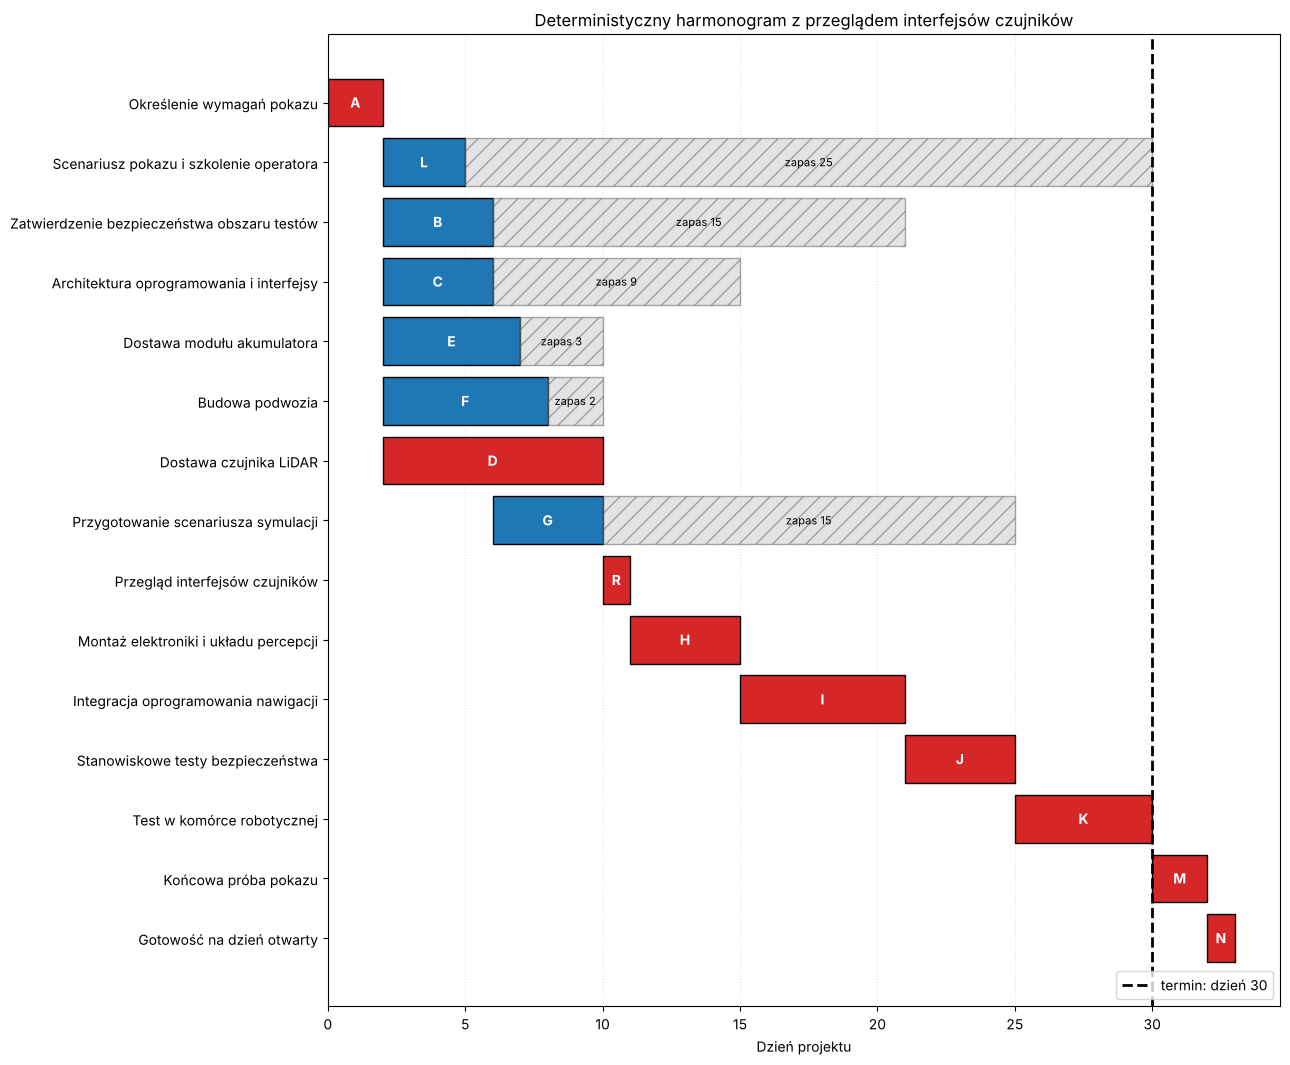

In [24]:
# Pokaż miejsce przeglądu w harmonogramie, zanim ocenisz, czy zmniejszenie ryzyka uzasadnia koszt.
plot_project_gantt(mitigated_cpm, deadline=deadline, title='Deterministyczny harmonogram z przeglądem interfejsów czujników');


### Zadanie 6 — decyzja o ograniczeniu ryzyka

Skorzystaj z `risk_comparison` i wykresu zmienionego harmonogramu.

1. Czy przegląd zmienia deterministyczny czas projektu?
2. Czy zmienia oczekiwany czas projektu według PERT?
3. Czy zmienia przybliżone prawdopodobieństwo ukończenia przed terminem oceny ryzyka?
4. Czy dodasz przegląd za 900 PLN? Uzasadnij decyzję ryzykiem harmonogramu i kosztem.
5. Czym ta decyzja różni się od prostego skrócenia zadania?

> **Rozwiązanie zadania 6.**
>
> 1. **Deterministyczny czas się nie zmienia: 33 dni.** Przegląd R dodaje 1 dzień na ścieżce krytycznej (A → D → **R** → H → …), ale H skraca się z 5 do 4 dni.
> 2. **Oczekiwany czas PERT spada** z 35,67 do **35,17 dnia**. Średnia H spada z 5,5 do 4,0 dnia, więcej niż kosztuje 1 dzień przeglądu.
> 3. **Prawdopodobieństwo ukończenia do dnia 36 rośnie** z ≈ 55% do **≈ 64%** (z: 0,13 → 0,35). Wariancja ścieżki spada z 6,33 do 5,75 dnia², bo H ma wąskie oszacowania (3, 4, 5) zamiast (4, 5, 9).
> 4. **Tak, dodałbym przegląd za 900 PLN.** Za mniej niż koszt jednego dnia skracania H (1400 PLN) czy I (1600 PLN) zyskuję ok. **+8–9 punktów procentowych** szansy na termin i krótszy pesymistyczny ogon rozkładu (p90 w Monte Carlo spada o ok. 0,6 dnia). Przy dniu otwartym z ustaloną datą przewidywalność jest warta więcej niż sama średnia.
> 5. **Skracanie zadania** (crashing) kupuje krótszy czas deterministyczny: wykres Gantta się kurczy, ale niepewność zostaje. **Przegląd** wydłuża sieć o nowe zadanie, a deterministycznie nic nie zmienia — jego wartość widać tylko w analizie ryzyka, bo zmniejsza zmienność i pesymistyczny scenariusz H. Ocena wymaga patrzenia na rozkład czasu, a nie tylko na CPM.

## Wyzwanie: symulacja Monte Carlo

Przybliżenie normalne PERT zakłada, że bieżąca ścieżka krytyczna pozostaje ścieżką wyznaczającą zakończenie. Symulacja sprawdza to założenie przez wielokrotne losowanie czasów i ponowne obliczanie czasu projektu.

Używamy przeskalowanego rozkładu beta z parametrami kształtu dobranymi tak, aby oczekiwana wartość losowanego czasu odpowiadała średniej PERT:

$$
E = \frac{a + 4m + b}{6}
$$

Symulacja nadal jest przybliżeniem, ale pokazuje ograniczenie: w różnych wylosowanych scenariuszach ścieżki krytyczne mogą się różnić.

### Funkcje symulacji: wylosowane dni zadań → rozkład czasu zakończenia

`sample_pert_beta_durations(tasks, rng, weight)` zwraca tablicę czasów zgodną z kolejnością wierszy. `project_duration_from_duration_vector` oblicza dzień zakończenia przejściem w przód, opcjonalnie korzystając z gotowego grafu i kolejności. `monte_carlo_project_duration(tasks, trials, seed)` powtarza kroki z odtwarzalnymi losowaniami i zwraca Series dni zakończenia. Dopiero z tej serii obliczamy średnie, kwantyle, częstości spełnienia terminu i wykresy.

In [25]:
# Zachowaj kolejność między próbami, lecz losuj nowe czasy — koniec mogą wyznaczać różne ścieżki.
def sample_pert_beta_durations(tasks, rng, weight=4):
    """Losuje wektor czasów zgodny z wierszami z przeskalowanych rozkładów beta-PERT.

    tasks ma liczbowe `a`, `m`, `b` w dniach, gdzie a <= m <= b.
    rng to numpy.random.Generator przekazany przez wywołującego; weight
    domyślnie 4 daje średnią (a+4m+b)/6 każdego zadania o zmiennym czasie.
    Zwraca tablicę NumPy float w kolejności wierszy wejściowych. Zadania
    z a bliskim b są deterministyczne; pozostałe czasy to niezależne
    losowania beta przeskalowane do [a,b]. Korzysta z NumPy i zmienia stan
    rng; nie oblicza grafu ani terminu, nie sprawdza oszacowań wejściowych."""
    a = tasks["a"].to_numpy(dtype=float)
    m = tasks["m"].to_numpy(dtype=float)
    b = tasks["b"].to_numpy(dtype=float)

    sampled = np.empty(len(tasks), dtype=float)
    # Stałe czasy pomijają obliczenia parametrów beta wymagające dzielenia przez szerokość przedziału.
    deterministic = np.isclose(a, b)
    sampled[deterministic] = a[deterministic]

    variable = ~deterministic
    width = b[variable] - a[variable]
    alpha = 1 + weight * (m[variable] - a[variable]) / width
    beta = 1 + weight * (b[variable] - m[variable]) / width
    sampled[variable] = a[variable] + rng.beta(alpha, beta) * width
    return sampled


def project_duration_from_duration_vector(tasks, duration_values, graph=None, order=None):
    """Oblicza wylosowany czas zakończenia wyłącznie przejściem w przód.

    tasks zawiera `id` i listy `predecessors`; duration_values to sekwencja
    liczb w dniach zgodna z kolejnością wierszy. Opcjonalne graph i order
    oznaczają pasujący DiGraph i topologiczną kolejność ID; przy None
    tworzy je build_project_graph/NetworkX. Zwraca największy najwcześniejszy
    koniec w dniach. Ponowne użycie graph/order pozwala nie budować tej samej
    topologii w każdej próbie. Nie zwraca zapasów, prawdopodobieństw ani tabeli CPM."""
    # Osobne wywołanie buduje graf; symulacja wielokrotna przekazuje gotowy graf i kolejność.
    if graph is None:
        graph = build_project_graph(tasks)
    if order is None:
        order = list(nx.topological_sort(graph))

    duration = dict(zip(tasks["id"], duration_values))
    earliest_finish = {}
    for task_id in order:
        predecessor_finishes = [earliest_finish[p] for p in graph.predecessors(task_id)]
        earliest_start = max(predecessor_finishes) if predecessor_finishes else 0
        earliest_finish[task_id] = earliest_start + duration[task_id]
    return max(earliest_finish.values())


def monte_carlo_project_duration(tasks, trials=3000, seed=42):
    """Losuje pełne harmonogramy i zwraca ich czasy zakończenia projektu.

    tasks to niepusty DataFrame z `id`, `predecessors` i poprawnymi `a`,
    `m`, `b` w dniach. trials jest dodatnią liczbą całkowitą, domyślnie 3000;
    seed domyślnie 42 zapewnia odtwarzalne losowania NumPy. Raz buduje graf
    i kolejność, w każdej próbie losuje czasy i wykonuje przejście w przód,
    więc ścieżka wyznaczająca koniec może się zmieniać. Zwraca pandas Series
    o nazwie project_duration z jednym czasem w dniach na próbę. Korzysta z
    build_project_graph, sample_pert_beta_durations i
    project_duration_from_duration_vector. Nie rysuje i nie wybiera terminu;
    wyniki zależą od oszacowań oraz założeń modelu."""
    rng = np.random.default_rng(seed)
    graph = build_project_graph(tasks)
    order = list(nx.topological_sort(graph))
    finishes = np.empty(trials, dtype=float)

    # W każdej próbie oblicz końce według poprzedników zamiast utrwalać oczekiwaną ścieżkę krytyczną.
    for trial in range(trials):
        sampled = sample_pert_beta_durations(tasks, rng)
        finishes[trial] = project_duration_from_duration_vector(tasks, sampled, graph=graph, order=order)

    return pd.Series(finishes, name="project_duration")


In [26]:
# Odtwarzalne losowania pozwalają porównywać modele bez przypadkowych zmian ziarna generatora.
sim_original = monte_carlo_project_duration(project_tasks, trials=3000, seed=1)
sim_mitigated = monte_carlo_project_duration(mitigated_tasks, trials=3000, seed=1)

simulation_summary = pd.DataFrame([
    {
        "case": "original",
        "mean": sim_original.mean(),
        "p50": sim_original.quantile(0.50),
        "p90": sim_original.quantile(0.90),
        "prob_finish_by_risk_deadline": (sim_original <= risk_deadline).mean(),
    },
    {
        "case": "with sensor interface review",
        "mean": sim_mitigated.mean(),
        "p50": sim_mitigated.quantile(0.50),
        "p90": sim_mitigated.quantile(0.90),
        "prob_finish_by_risk_deadline": (sim_mitigated <= risk_deadline).mean(),
    },
])

simulation_summary


,case,mean,p50,p90,prob_finish_by_risk_deadline
0,original,35.838491,35.745807,39.316786,0.536333
1,with sensor interface review,35.264299,35.124459,38.688530,0.621667


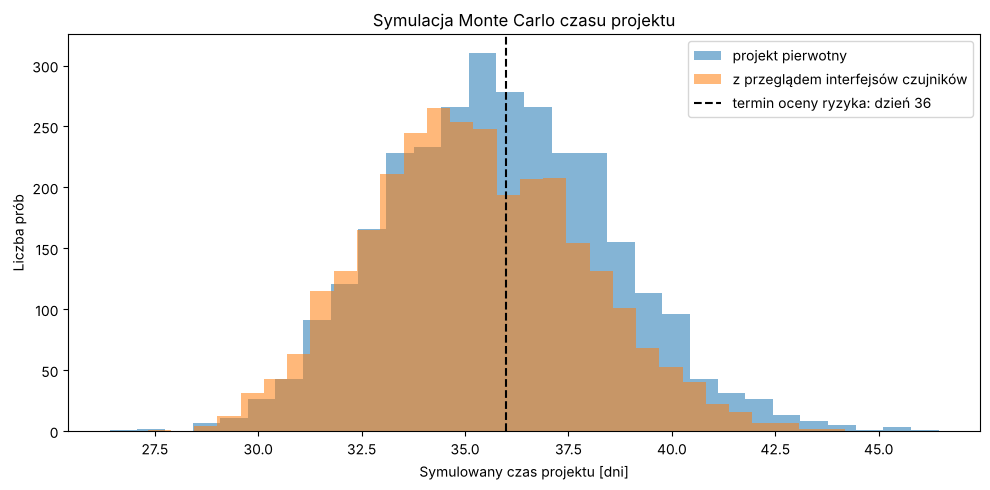

In [27]:
# Nałóż rozkłady czasu zakończenia i wspólny termin, aby pokazać więcej niż samą średnią.
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(sim_original, bins=30, alpha=0.55, label="projekt pierwotny")
ax.hist(sim_mitigated, bins=30, alpha=0.55, label="z przeglądem interfejsów czujników")
ax.axvline(risk_deadline, linestyle="--", color="black", label=f"termin oceny ryzyka: dzień {risk_deadline}")
ax.set_xlabel('Symulowany czas projektu [dni]')
ax.set_ylabel('Liczba prób')
ax.set_title('Symulacja Monte Carlo czasu projektu')
ax.legend()
plt.tight_layout()


### Pytania do wyzwania

1. Porównaj przybliżenie normalne PERT z Monte Carlo. Czy wyniki są bliskie?
2. Który wynik pokażesz kierownictwu i dlaczego?
3. Rozszerz symulację na wybrany plan dostaw i skracania zadań.
4. Znajdź plan dający co najmniej 80% symulowanego prawdopodobieństwa ukończenia przed terminem oceny ryzyka.

## Moje rozwiązanie wyzwania Monte Carlo

**1–2. Porównanie PERT i Monte Carlo:**

In [28]:
# Wyzwanie 1: przybliżenie normalne PERT kontra częstość z symulacji.
challenge_compare = pd.DataFrame([
    {"case": "original", "PERT_normal_prob": pert_stats["approx_probability_finish_by_deadline"],
     "MonteCarlo_prob": (sim_original <= risk_deadline).mean(),
     "PERT_expected": pert_stats["expected_project_duration"], "MC_mean": sim_original.mean()},
    {"case": "with sensor interface review", "PERT_normal_prob": mitigated_pert_stats["approx_probability_finish_by_deadline"],
     "MonteCarlo_prob": (sim_mitigated <= risk_deadline).mean(),
     "PERT_expected": mitigated_pert_stats["expected_project_duration"], "MC_mean": sim_mitigated.mean()},
])
display(challenge_compare.round(3))

,case,PERT_normal_prob,MonteCarlo_prob,PERT_expected,MC_mean
0,original,0.553,0.536,35.667,35.838
1,with sensor interface review,0.636,0.622,35.167,35.264


> Wyniki są **bliskie**: dla projektu pierwotnego PERT daje ≈ 55,3%, a Monte Carlo ≈ 53,6%; z przeglądem ≈ 63,6% wobec ≈ 62,2%. Symulacja jest systematycznie **odrobinę bardziej pesymistyczna** (średnia ok. 35,8 zamiast 35,67 dnia). Koniec projektu to **maksimum** kilku ścieżek, a gdy ścieżka przez F lub E wylosuje się długa, przejmuje rolę krytycznej — PERT tego nie uwzględnia.
>
> **Kierownictwu pokazałbym wynik Monte Carlo** (prawdopodobieństwo i p90), z uwagą, że zależy od oszacowań a, m, b. Uwzględnia przełączanie ścieżek i pokazuje cały rozkład („w 9 na 10 przypadków skończymy do dnia ~39”), a nie jedną liczbę z założeniem normalności. PERT zostaje jako szybka kontrola na papierze.

**3–4. Symulacja wybranego planu i szukanie planu z ≥ 80% szans.**

Funkcje `apply_crash_plan` i `apply_duration_changes` nie zmieniają kolumn PERT, więc potrzebne jest **założenie**: zmiana planu przesuwa oszacowania (a, m, b) o tyle dni, o ile zmienił się czas deterministyczny. Przyspieszenie usuwa stałą część pracy, a szerokość niepewności b − a zostaje bez zmian. Przegląd R zmienia H tak jak w zadaniu 6 (z odjęciem ewentualnej redukcji H).

In [29]:
# Plan dostaw/skracania przeniesiony na oszacowania PERT: (a, m, b) przesuwam o tę samą liczbę dni,
# o którą zmienił się czas deterministyczny (założenie: przyspieszenie usuwa stałą część pracy,
# a niepewność — szerokość b − a — zostaje taka sama). Dolna granica a ≥ 0,5 dnia.
def apply_plan_to_pert(tasks, supplier_changes=None, crash_reductions=None, min_days=0.5):
    """Zwraca kopię zadań z czasem deterministycznym i oszacowaniami PERT po zmianach planu."""
    planned = apply_crash_plan(apply_duration_changes(tasks, supplier_changes or {}), crash_reductions or {})
    shift = dict(zip(tasks["id"], tasks["duration"] - planned["duration"].to_numpy()))
    planned = planned.copy()
    for col in ("a", "m", "b"):
        planned[col] = [max(min_days, value - shift.get(task_id, 0))
                        for task_id, value in zip(planned["id"], planned[col])]
    # Utrzymaj porządek a <= m <= b po przycięciu do min_days.
    planned["m"] = planned[["a", "m"]].max(axis=1)
    planned["b"] = planned[["m", "b"]].max(axis=1)
    return planned


def simulate_plan(tasks, supplier_changes=None, crash_reductions=None, with_review=False,
                  deadline=36, trials=3000, seed=1):
    """Monte Carlo dla planu (opcjonalnie z przeglądem R); zwraca słownik statystyk."""
    planned = apply_plan_to_pert(tasks, supplier_changes, crash_reductions)
    if with_review:
        # Przegląd ustawia H na 4 dni i PERT (3,4,5); jeśli H skrócono, odejmij tę redukcję.
        h_cut = (crash_reductions or {}).get("H", 0)
        planned = add_sensor_interface_review(planned)
        h = planned.index[planned["id"] == "H"][0]
        planned.loc[h, ["duration", "a", "m", "b"]] = [max(0, 4 - h_cut), max(0.5, 3 - h_cut),
                                                       max(0.5, 4 - h_cut), max(0.5, 5 - h_cut)]
    sim = monte_carlo_project_duration(planned, trials=trials, seed=seed)
    return {"mean": sim.mean(), "p50": sim.quantile(0.5), "p90": sim.quantile(0.9),
            "prob_by_deadline": (sim <= deadline).mean(), "sim": sim}


# Wyzwanie 3: Monte Carlo dla planu wybranego w zadaniu 4 (bez przeglądu i z przeglądem).
plan_rows = []
for label, sup, crash, review, cost in [
    ("bazowy (standard)", {}, {}, False, 0),
    ("bazowy + przegląd R", {}, {}, True, 900),
    ("wybrany: express LiDAR + F−1", selected_supplier_changes, selected_crash_reductions, False, 3300),
    ("wybrany + przegląd R", selected_supplier_changes, selected_crash_reductions, True, 4200),
]:
    stats = simulate_plan(project_tasks, sup, crash, with_review=review, deadline=risk_deadline, trials=3000, seed=1)
    plan_rows.append({"plan": label, "extra_cost_PLN": cost, "MC_mean": stats["mean"], "MC_p90": stats["p90"],
                      "prob_by_day_36": stats["prob_by_deadline"]})
display(pd.DataFrame(plan_rows).round(3))

# Wyzwanie 4: najtańszy plan z co najmniej 80% szans (wstępny przegląd 800 prób, potem potwierdzenie 3000).
supplier_map = {"standard suppliers": {}, "express LiDAR": {"D": 5},
                "express battery": {"E": 3}, "express both": {"D": 5, "E": 3}}
screen = []
for row in plans[plans.total_extra_cost <= 4200].itertuples(index=False):
    for review in (False, True):
        cost = row.total_extra_cost + (900 if review else 0)
        if cost > 4200:
            continue
        stats = simulate_plan(project_tasks, supplier_map[row.supplier_choice], row.crash_reductions,
                              with_review=review, deadline=risk_deadline, trials=800, seed=7)
        screen.append({"supplier_choice": row.supplier_choice, "crash_reductions": row.crash_reductions,
                       "review": review, "deterministic_days": row.project_duration,
                       "extra_cost_PLN": cost, "prob_screen": stats["prob_by_deadline"]})
screen = pd.DataFrame(screen).sort_values(["extra_cost_PLN", "prob_screen"], ascending=[True, False])
shortlist = screen[screen.prob_screen >= 0.75].head(8).copy()
shortlist["prob_confirmed_3000"] = [
    simulate_plan(project_tasks, supplier_map[r.supplier_choice], r.crash_reductions, with_review=r.review,
                  deadline=risk_deadline, trials=3000, seed=1)["prob_by_deadline"]
    for r in shortlist.itertuples(index=False)]
display(shortlist.round(3))

,plan,extra_cost_PLN,MC_mean,MC_p90,prob_by_day_36
0,bazowy (standard),0,35.838,39.317,0.536
1,bazowy + przegląd R,900,35.264,38.689,0.622
2,wybrany: express LiDAR + F−1,3300,33.705,36.902,0.821
3,wybrany + przegląd R,4200,33.140,36.229,0.883


,supplier_choice,crash_reductions,review,deterministic_days,extra_cost_PLN,prob_screen,prob_confirmed_3000
46,express LiDAR,"{'F': 0, 'H': 0, 'I': 0, 'J': 0, 'K': 0}",False,31,2400,0.785,0.779
22,standard suppliers,"{'F': 0, 'H': 2, 'I': 0, 'J': 0, 'K': 0}",False,31,2800,0.792,0.791
20,standard suppliers,"{'F': 0, 'H': 1, 'I': 1, 'J': 0, 'K': 0}",False,31,3000,0.792,0.791
18,standard suppliers,"{'F': 0, 'H': 1, 'I': 0, 'J': 1, 'K': 0}",False,31,3100,0.792,0.791
13,standard suppliers,"{'F': 0, 'H': 0, 'I': 2, 'J': 0, 'K': 0}",False,31,3200,0.792,0.791
35,standard suppliers,"{'F': 1, 'H': 1, 'I': 0, 'J': 0, 'K': 0}",True,32,3200,0.750,0.745
47,express LiDAR,"{'F': 0, 'H': 0, 'I': 0, 'J': 0, 'K': 0}",True,31,3300,0.845,0.856
51,express LiDAR,"{'F': 1, 'H': 0, 'I': 0, 'J': 0, 'K': 0}",False,30,3300,0.815,0.821


> **Wnioski z wyzwania 3–4** (przy przyjętym założeniu o przesunięciu oszacowań):
>
> - **Plan wybrany w zadaniu 4** (ekspresowy LiDAR + F − 1, 3300 PLN) daje w symulacji ok. **82%** szans na zakończenie do dnia 36 (średnio ok. 33,7 dnia) — spełnia próg 80%, ale z niewielkim marginesem.
> - **Z przeglądem interfejsów** (razem 4200 PLN) szansa rośnie do ok. **88%**, a p90 spada poniżej 36,5 dnia.
> - Przegląd tabeli (potwierdzony 3000 prób): tańsze plany zatrzymują się **tuż poniżej progu** — sam ekspresowy LiDAR (2400 PLN) daje ≈ 78%, a skrócenie H o 2 dni (2800 PLN) ≈ 79%. **Najtańsze plany z ≥ 80% kosztują 3300 PLN:** ekspresowy LiDAR + przegląd R (≈ 86%, ale 31 dni deterministycznie) albo plan wybrany w zadaniu 4 (≈ 82%, 30 dni). Rekomendowałbym **ekspresowy LiDAR + F − 1 + przegląd R (4200 PLN, ≈ 88%)**, bo jako jedyny w tej grupie spełnia **jednocześnie** cel 30 dni i daje wyraźny zapas nad progiem 80%. Przy wynikach tak blisko 80% różnice rzędu 1–2 p.p. mieszczą się w szumie symulacji.

## Szablon raportu końcowego

Przygotuj krótki raport:

### 1. Bazowy CPM

- Czas projektu:
- Ścieżka krytyczna:
- Trzy zadania z największym zapasem czasu:
- Jedno zdanie wyjaśniające znaczenie zapasu:

### 2. Wybór dostaw

- Zalecane zmiany dostaw:
- Zaoszczędzone dni:
- Koszt:
- Dlaczego druga opcja jest lub nie jest przydatna:

### 3. Skracanie czasu zadań

- Zalecane redukcje:
- Nowy czas projektu:
- Łączny koszt:
- Nowa ścieżka krytyczna:

### 4. Ryzyko PERT

- Oczekiwany czas projektu:
- Prawdopodobieństwo spełnienia terminu:
- Główne źródło ryzyka:
- Zalecenie dotyczące przeglądu interfejsów czujników:

### 5. Refleksja

W 3–5 zdaniach wyjaśnij różnice między projektowym wykresem Gantta z tego laboratorium a wykresem stanowisk z laboratorium 4.

## Mój raport końcowy

### 1. Bazowy CPM
- **Czas projektu:** 33 dni.
- **Ścieżka krytyczna:** A → D → H → I → J → K → M → N.
- **Trzy zadania z największym zapasem czasu:** L — scenariusz i szkolenie operatora (25 dni), B — zatwierdzenie bezpieczeństwa (15 dni), G — scenariusz symulacji (15 dni).
- **Znaczenie zapasu:** zapas mówi, o ile dni zadanie może się opóźnić bez przesunięcia końca projektu. Przyspieszanie zadań z zapasem nic nie daje, a zadania bez zapasu trzeba pilnować w pierwszej kolejności.

### 2. Wybór dostaw
- **Zalecane zmiany dostaw:** tylko **ekspresowy LiDAR** (D: 8 → 5 dni).
- **Zaoszczędzone dni:** 2 dni projektu (33 → 31).
- **Koszt:** 2400 PLN (1200 PLN za dzień projektu).
- **Druga opcja:** ekspresowy akumulator jest nieprzydatny — E ma 3 dni zapasu (po przyspieszeniu LiDAR-u nadal 1 dzień), więc 1200 PLN nie oszczędza ani jednego dnia projektu.

### 3. Skracanie czasu zadań
- **Zalecane redukcje:** budowa podwozia **F o 1 dzień** (900 PLN), razem z ekspresowym LiDAR-em.
- **Nowy czas projektu:** **30 dni** — cel kierownictwa spełniony.
- **Łączny koszt:** **3300 PLN** dopłaty (najtańszy z 778 planów spełniających termin; samo skracanie H/I/J/K kosztowałoby co najmniej 4400 PLN).
- **Nowa ścieżka krytyczna:** A → {D, E, F} → H → I → J → K → M → N — trzy równoległe łańcuchy, bo LiDAR, akumulator i podwozie kończą się razem w dniu 7.

### 4. Ryzyko PERT
- **Oczekiwany czas projektu:** 35,67 dnia (σ ≈ 2,52 dnia) w wariancie bazowym; dla wybranego planu ok. 33,7 dnia (Monte Carlo).
- **Prawdopodobieństwo spełnienia terminu (dzień 36):** ≈ 55% (PERT) / ≈ 54% (Monte Carlo) bazowo; ok. 82% dla wybranego planu i ok. 88% z przeglądem.
- **Główne źródło ryzyka:** dostawa LiDAR-u (D) i test w komórce robotycznej (K) — największe wariancje na ścieżce krytycznej, a także integracja nawigacji (I).
- **Zalecenie dotyczące przeglądu interfejsów czujników:** **dodać** (900 PLN). Nie zmienia czasu deterministycznego, ale skraca oczekiwany czas o 0,5 dnia i podnosi szansę na termin o ok. 6–9 p.p. — taniej niż jakikolwiek dzień skracania zadań.

### 5. Refleksja
Wykres Gantta w laboratorium 4 miał w wierszach **stanowiska**: paski w jednym wierszu nie mogły się nakładać, bo maszyna obsługuje jeden zestaw naraz, a o kolejności decydował solver przez zmienne binarne. Tutaj wiersz to **zadanie projektowe**, a paski różnych wierszy mogą się dowolnie nakładać. Ograniczeniem jest wyłącznie kolejność logiczna (poprzednicy), a zasoby są nieograniczone. Dlatego w laboratorium 4 wąskim gardłem był przeciążony zasób, a tutaj jest nim łańcuch zależności bez zapasu czasu. Projektowy wykres pokazuje też zapas, którego wykres stanowisk nie miał — zamiast niego widać tam przestoje maszyn.